In [2]:
!uv pip install av

Using Python 3.13.18 environment at: /usr
Checked 1 package in 75ms


In [3]:
import itertools
from pathlib import Path

import av
import matplotlib.pyplot as plt
import pandas as pd
import skimage
from tqdm.auto import tqdm
import numpy as np


LARGO_PENDULO_SIN_BASE = 73.7 /100
LARGO_PENDULO_BASE = 77.8 /100

SIGMA_L = 0.5 / 100

ANCHO_PENDULO = 3.0 / 1000
SIGMA_C = 0.2 / 1000 # error del calibre
SIGMA_T = 1 / 59.96
SIGMA_P = 0.00001 # Error de medicion del tiempo

## Analizar primer fotograma

**Objetivo:** encontrar la posición del péndulo para un fotograma.

In [4]:
def cargar_primer_fotograma(archivo):
    with av.open(archivo) as container:
        fotograma = next(container.decode(video=0))
        fotograma = fotograma.to_ndarray(format="gray")
    return fotograma

In [5]:
def cargar_fotograma(archivo, indice):
    with av.open(archivo) as container:
        for i, fotograma in enumerate(container.decode(video=0)):
            if i == indice:
                return fotograma.to_ndarray(format="gray")

    return None

In [6]:
def grafica_fotogramas(archivo, rango):
    fig, axes = plt.subplots(len(rango), 1, figsize=(10, 4 * len(rango)))

    if len(rango) == 1:
        axes = [axes]

    for ax, sample in zip(axes, rango):
        fotograma = cargar_fotograma(archivo, sample).T

        if fotograma is not None:
            ax.imshow(fotograma, cmap="gray")
            ax.set_title(f"Fotograma {sample}")
            ax.axis("off")

    plt.tight_layout()
    plt.show()

### Una propuesta:

1. Cargar una imagen
2. Restar el fondo (opcional)
3. Recortar la imagen (opcional)
4. Segmentar:
    - Mascara: pixeles mayores a un valor umbral de intensidad
    - Refinar la mascara con operadores morfológicos
5. Encontrar el centroide

In [27]:
#grafica_fotogramas("/content/drive/MyDrive/Videos Recortados/oscilacion#larga#0.MOV", [0, 50, 100, 150, 200])

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [153]:
import av
from PIL import Image
from google.colab import files

def descargar_fotogramas(ruta_video, indices_objetivo, formato="gray"):
    objetivos = {i - 1 for i in indices_objetivo}
    max_indice = max(objetivos)

    with av.open(ruta_video) as container:
        for idx, frame in enumerate(container.decode(video=0)):
            if idx in objetivos:
                img_array = frame.to_ndarray(format=formato)
                nombre_archivo = f"fotograma_{idx + 1}.png"

                # Guardar temporalmente en Colab y disparar la descarga
                Image.fromarray(img_array).save(nombre_archivo)
                files.download(nombre_archivo)
                print(f"Descargando: {nombre_archivo}")

            if idx >= max_indice:
                break

# Ejecutar con tu video
ruta_video = "/content/drive/MyDrive/mi_carpetita/IMG_1555.MOV"
descargar_fotogramas(ruta_video, [1, 100], formato="gray")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descargando: fotograma_1.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descargando: fotograma_100.png


In [40]:
import av
from PIL import Image
from google.colab import files

def cargar_primer_fotograma(archivo):
    with av.open(archivo) as container:
        fotograma = next(container.decode(video=0))
        fotograma = fotograma.to_ndarray(format="gray")
    return fotograma

# 1. Extraer la matriz del fotograma
ruta = '/content/drive/MyDrive/mi_carpetita/IMG_1555.MOV'
img_array = cargar_primer_fotograma(ruta)

# Verificar dimensiones exactas (alto, ancho)
print(f"Resolución exacta: {img_array.shape[1]}x{img_array.shape[0]} píxeles")

# 2. Guardar como PNG (sin pérdida de calidad) con la resolución nativa 1:1
nombre_salida = 'primer_fotograma.png'
Image.fromarray(img_array).save(nombre_salida)

# 3. Descargar el archivo a tu computadora
files.download(nombre_salida)

Resolución exacta: 3840x2160 píxeles


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

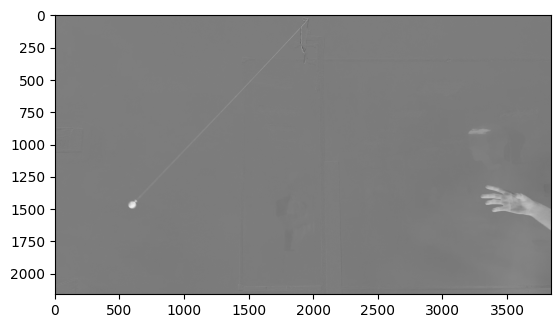

In [297]:
imagen_original = cargar_primer_fotograma("/content/drive/MyDrive/mi_carpetita/IMG_1556.MOV")
fondo = np.array(Image.open('/content/drive/MyDrive/mi_carpetita/superfotograma!.png').convert('L'))
fondo = fondo.astype(float)
imagen_original = imagen_original.astype(float)  # importante

imagen_menos_fondo = fondo - imagen_original
plt.imshow(imagen_menos_fondo,cmap="gray")

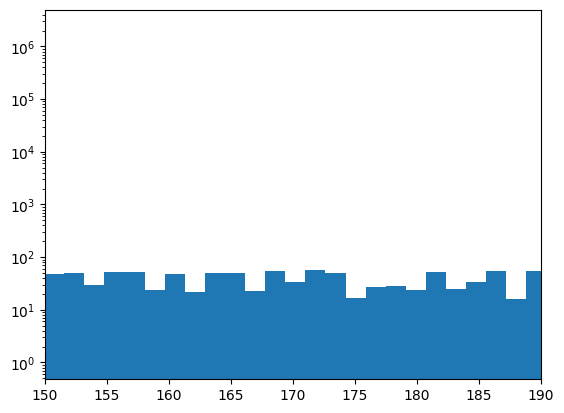

In [291]:
plt.hist(imagen_menos_fondo.flatten(), bins=256)
plt.yscale("log")
plt.xlim(150, 190)
plt.show()



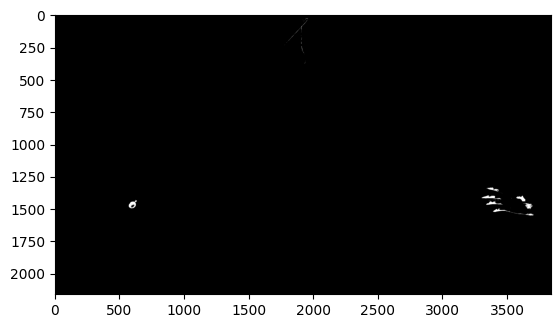

In [298]:
imagen_menos_fondo_circulares = (imagen_menos_fondo > 100) & (imagen_menos_fondo < 200)
plt.imshow(imagen_menos_fondo_circulares,cmap="gray")

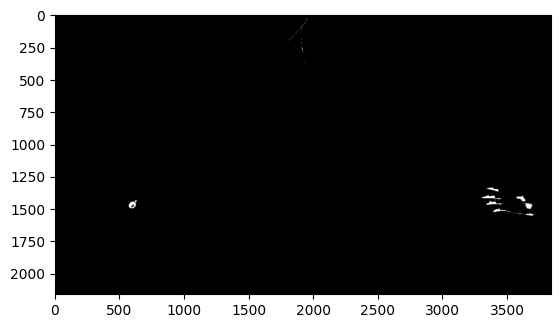

In [301]:
circulo = skimage.morphology.closing(imagen_menos_fondo_circulares, skimage.morphology.disk(2))
plt.imshow(circulo,cmap="gray")

Centroide en x=599.10, y=1469.31 | Área=2139.0 px


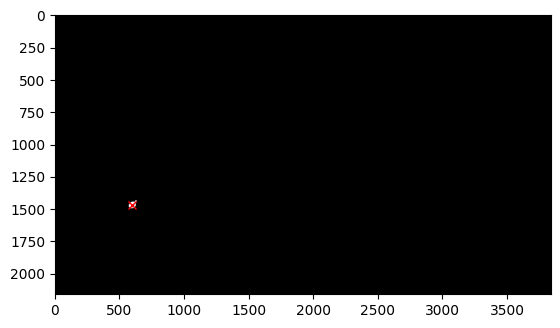

In [302]:
from skimage.measure import label, regionprops
import numpy as np

# Etiquetar cada mancha blanca independiente
etiquetas = label(circulo > 0)
regiones = regionprops(etiquetas)

# Buscar la región con mayor área (la pelotita)
pelotita = max(regiones, key=lambda r: r.area)

# Crear una imagen limpia solo con esa región
solo_pelotita = (etiquetas == pelotita.label)

# De paso, ya tienes el centroide exacto (fila, columna) -> (y, x)
y_centro, x_centro = pelotita.centroid
print(f"Centroide en x={x_centro:.2f}, y={y_centro:.2f} | Área={pelotita.area} px")

plt.imshow(solo_pelotita, cmap="gray")
plt.plot(x_centro, y_centro, 'rx')  # Marca el centro en rojo

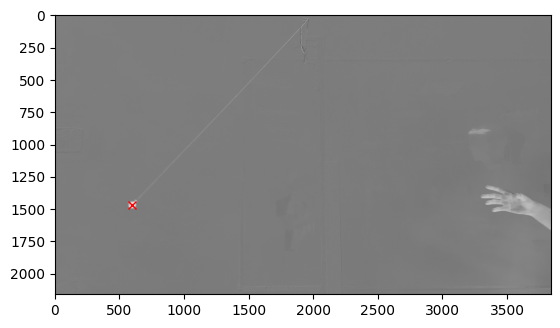

In [303]:
plt.imshow(solo_pelotita, cmap="gray")
plt.plot(x_centro, y_centro, 'rx')  # Marca el centro en rojo
plt.imshow(imagen_menos_fondo,cmap="gray")


## Analizar un video completo

**Objetivo**: encontrar la posición del péndulo para cada fotograma.

Actualizar la función `procesar_fotograma`
usando el código que definieron antes para procesar un fotograma.

In [31]:
def procesar_video(archivo, *, n_fotogramas: int | None = None):
    with av.open(archivo) as container:
        video = container.streams.video[0]

        n_fotogramas = video.frames if n_fotogramas is None else n_fotogramas

        iter_video = container.decode(video=0)
        iter_video = itertools.islice(iter_video, n_fotogramas)
        iter_video = tqdm(iter_video, total=n_fotogramas, leave=False)

        data = {
            "t": [],
            "x": [],
            "y": [],
        }
        for fotograma in iter_video:
            data["t"].append(fotograma.time)
            x, y = procesar_fotograma(fotograma.to_ndarray(format="gray"))
            data["x"].append(x)
            data["y"].append(y)

    return pd.DataFrame(data)

def optimizado_sampleado_procesar_video(archivo, *, paso=10, n_fotogramas=None):

    with av.open(archivo) as container:
        iter_video = container.decode(video=0)

        if n_fotogramas is not None:
            iter_video = itertools.islice(iter_video, 0, n_fotogramas, paso)
        else:
            iter_video = itertools.islice(iter_video, 0, None, paso)

        data = {"t": [], "x": [], "y": []}

        for fotograma in tqdm(iter_video, leave=False):
            imagen = fotograma.to_ndarray(format="gray")[800:950]

            imagen = skimage.morphology.closing(
                imagen, skimage.morphology.disk(16)
            )

            pos = skimage.measure.centroid(imagen < 220)

            data["t"].append(fotograma.time)
            data["x"].append(pos[1])
            data["y"].append(pos[0])

    return pd.DataFrame(data)




def procesar_fotograma(imagen) -> tuple[float, float]:
  fondo = cargar_primer_fotograma("/content/drive/MyDrive/Videos Recortados/Fondo.MOV").T

  fondo = fondo.astype(float)
  imagen = imagen.astype(float)  # importante

  imagen = imagen[800:950]
  imagen = skimage.morphology.closing(imagen, skimage.morphology.disk(16))

  #plt.hist(imagen.flatten())
  imagen = imagen < 220

  # Segmentar pendulo
  pos = skimage.measure.centroid(imagen)
  pos_columna = pos.copy()
  pos_columna[0] = pos[1]
  pos_columna[1] = pos[0]

  return pos_columna[0], pos_columna[1]

In [32]:
archivo = Path("/content/drive/MyDrive/Videos Recortados/oscilacion#corta#0.MOV")

In [33]:
def optimizado_sampleado_procesar_video(archivo, *, paso=10, n_fotogramas=None):
    with av.open(archivo) as container:
        iter_video = container.decode(video=0)

        if n_fotogramas is not None:
            iter_video = itertools.islice(iter_video, 0, n_fotogramas, paso)
        else:
            iter_video = itertools.islice(iter_video, 0, None, paso)

        data = {"t": [], "x": [], "y": []}

        for fotograma in tqdm(iter_video, leave=False):
            # Acá estaba el problema: faltaba el .T antes del recorte [800:950]
            imagen = fotograma.to_ndarray(format="gray").T[800:950]

            imagen = skimage.morphology.closing(
                imagen, skimage.morphology.disk(16)
            )

            pos = skimage.measure.centroid(imagen < 220)

            data["t"].append(fotograma.time)
            data["x"].append(pos[1])
            data["y"].append(pos[0])

    return pd.DataFrame(data)

In [21]:
clase_13_corta_sampleado = optimizado_sampleado_procesar_video(
    archivo,
)
clase_13_corta_sampleado.head(2)

0it [00:00, ?it/s]

,t,x,y
0,0.000000,521.736956,95.860741
1,0.166667,547.259127,96.304939


             t           x          y
0     0.000000  521.736956  95.860741
1     0.166667  547.259127  96.304939
2     0.333333  568.064482  95.838619
3     0.500000  576.375527  95.529184
4     0.666667  569.429595  95.763884
..         ...         ...        ...
135  22.513333  501.473762  95.443829
136  22.680000  521.509229  95.868259
137  22.846667  545.419232  96.260464
138  23.013333  565.191376  96.006415
139  23.213333  573.465400  95.995339

[140 rows x 3 columns] (150, 1080)


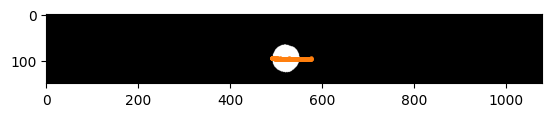

In [34]:
fondo = cargar_primer_fotograma("/content/drive/MyDrive/Videos Recortados/Fondo.MOV").T
imagen = cargar_primer_fotograma("/content/drive/MyDrive/Videos Recortados/oscilacion#corta#0.MOV").T
fondo = fondo.astype(float)
imagen = imagen.astype(float)  # importante
imagen = imagen[800:950]

imagen = skimage.morphology.closing(
    imagen, skimage.morphology.disk(16)
)
imagen = imagen < 220

plt.imshow(imagen ,cmap="gray")

print(clase_13_corta_sampleado, imagen.shape)

for pos_columna in clase_13_corta_sampleado[["x", "y"]].values:
  plt.scatter(*pos_columna, color="C1", s=5)



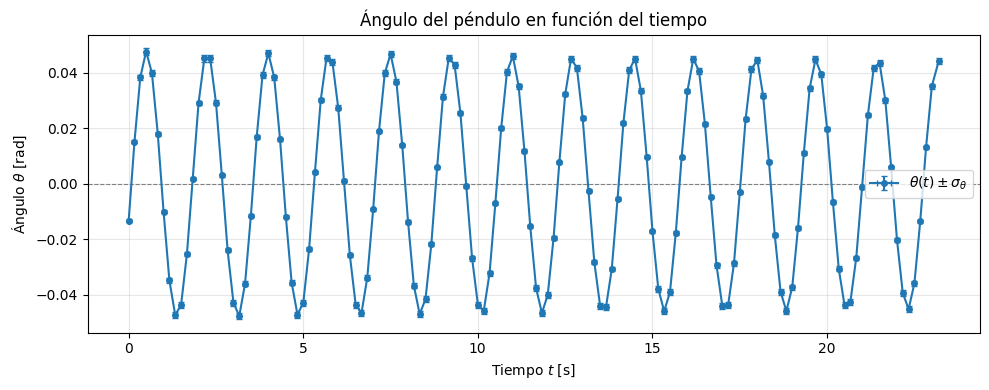

,t,sigma_t,theta_rad,sigma_theta_rad,theta_deg,sigma_theta_deg
0,0.000000,0.016678,-0.013224,0.000620,-0.757702,0.035539
1,0.166667,0.016678,0.015165,0.000639,0.868912,0.036620
2,0.333333,0.016678,0.038316,0.000971,2.195367,0.055638
3,0.500000,0.016678,0.047569,0.001134,2.725531,0.064987
4,0.666667,0.016678,0.039836,0.000997,2.282434,0.057132


In [35]:
# --- 1. CONSTANTES Y PARÁMETROS DEL EXPERIMENTO ---
# Podés cambiar a LARGO_PENDULO_SIN_BASE si midieron hasta el centro de masa
L = LARGO_PENDULO_BASE        # 0.778 m
sigma_L = SIGMA_L             # 0.005 m
sigma_t = SIGMA_T             # ~0.01667 s (1 / 59.96 fps)

# --- 2. CALIBRACIÓN PÍXEL -> METRO ---
# Medí cuántos píxeles de ancho tiene el objeto de referencia en el fotograma.
# Ejemplo: si la esfera/varilla mide D_REAL metros y ocupa D_PX píxeles en la foto:
D_REAL = 0.0450               # <-- Ajustar: diámetro de la esfera/objeto en metros (o ANCHO_PENDULO)
SIGMA_D_REAL = SIGMA_C        # 0.0002 m (error del calibre)
D_PX = 52.0                   # <-- Ajustar: ancho en píxeles medido en plt.imshow
SIGMA_D_PX = 1.0              # Error de apreciación en píxeles

# Factor de escala k (m / px) y su error propagado
k = D_REAL / D_PX
sigma_k = k * np.sqrt((SIGMA_D_REAL / D_REAL)**2 + (SIGMA_D_PX / D_PX)**2)

# Error de detección del centroide en píxeles
sigma_x_px = 0.5

# --- 3. PASAJE A POLARES (ÁNGULO Y ERRORES) ---
df_polar = clase_13_corta_sampleado.copy()

# Posición de equilibrio x0 (promedio entre el máximo y mínimo de la oscilación)
x0_px = 0.5 * (df_polar["x"].max() + df_polar["x"].min())
dx_px = df_polar["x"] - x0_px

# Desplazamiento horizontal X en metros y su incerteza
df_polar["X_m"] = dx_px * k
df_polar["sigma_X_m"] = np.sqrt((k * sigma_x_px)**2 + (dx_px * sigma_k)**2)

# Ángulo theta(t) = arcsin(X / L) en radianes
ratio = np.clip(df_polar["X_m"] / L, -0.999, 0.999)
df_polar["theta_rad"] = np.arcsin(ratio)

# Propagación de error para theta (en radianes)
factor_derivada = 1.0 / np.sqrt(1.0 - ratio**2)
df_polar["sigma_theta_rad"] = factor_derivada * np.sqrt(
    (df_polar["sigma_X_m"] / L)**2 + (df_polar["X_m"] * sigma_L / (L**2))**2
)

# Opcional: en grados
df_polar["theta_deg"] = np.degrees(df_polar["theta_rad"])
df_polar["sigma_theta_deg"] = np.degrees(df_polar["sigma_theta_rad"])
df_polar["sigma_t"] = sigma_t

# --- 4. GRÁFICO DE THETA(t) CON BARRAS DE ERROR ---
plt.figure(figsize=(10, 4))
plt.errorbar(
    df_polar["t"],
    df_polar["theta_rad"],
    xerr=df_polar["sigma_t"],
    yerr=df_polar["sigma_theta_rad"],
    fmt="o-",
    markersize=4,
    capsize=2,
    label=r"$\theta(t) \pm \sigma_\theta$"
)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel("Tiempo $t$ [s]")
plt.ylabel(r"Ángulo $\theta$ [rad]")
plt.title("Ángulo del péndulo en función del tiempo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

df_polar[["t", "sigma_t", "theta_rad", "sigma_theta_rad", "theta_deg", "sigma_theta_deg"]].head()

## Analizar todos los videos

Como analizar un video es lento,
se puede guardar las posiciones en un archivo intermedio.
Luego, se puede continuar el análisis a partir de ahí
(puede ser en un nuevo *notebook*).

In [36]:
archivos = Path("data").glob("*.mp4")  # archivos .MOV
archivos = list(archivos)

for archivo in tqdm(archivos):
    posiciones = procesar_video(archivo)
    posiciones.to_csv(archivo.with_suffix(".csv"), index=False)

0it [00:00, ?it/s]

## Super Testeo Definitivo Gravitatorio (G)

In [37]:
import itertools
from pathlib import Path
import av
import skimage
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


class GravedadCalculada:
    def __init__(
        self,
        df_polar_real: pd.DataFrame,
        nombre: str = "Experimento",
        largo_base: float = LARGO_PENDULO_BASE,
        largo_sin_base: float = LARGO_PENDULO_SIN_BASE,
        sigma_l: float = SIGMA_L,
    ):
        self.nombre = nombre
        self.largo_base = largo_base
        self.largo_sin_base = largo_sin_base
        self.largo_cm = 0.5 * (largo_base + largo_sin_base)
        self.sigma_l = sigma_l

        self.df_polar = df_polar_real
        self.df_fit = df_polar_real.dropna(
            subset=["t", "theta_rad", "sigma_theta_rad"]
        ).copy()
        self.t_data = self.df_fit["t"].values
        self.y_data = self.df_fit["theta_rad"].values
        self.y_err = self.df_fit["sigma_theta_rad"].values

        self._ajustar()

    # --- 1. PROCESAMIENTO DE VIDEO: LA POSTA (COMPLETO) Y LA SAMPLEADA ---
    @staticmethod
    def _procesar_fotograma(
        fotograma_gray: np.ndarray,
        recorte_y: tuple[int, int] = (800, 950),
        footprint=skimage.morphology.disk(16),
        umbral: float = 220,
    ) -> tuple[float, float]:
        """Procesa un único fotograma (ya transpuesto con .T) y devuelve (x, y)."""
        y_ini, y_fin = recorte_y
        imagen = fotograma_gray.T[y_ini:y_fin]
        imagen = skimage.morphology.closing(imagen, footprint)
        pos = skimage.measure.centroid(imagen < umbral)
        return pos[1], pos[0]  # (x, y)

    @classmethod
    def procesar_video_completo(
        cls,
        archivo: str | Path,
        n_fotogramas: int | None = None,
        recorte_y: tuple[int, int] = (800, 950),
        umbral: float = 220,
        radio_disco: int = 16,
    ) -> pd.DataFrame:
        """LA POSTA: Procesa todos los fotogramas del video uno por uno."""
        footprint = skimage.morphology.disk(radio_disco)
        with av.open(archivo) as container:
            video = container.streams.video[0]
            total = video.frames if n_fotogramas is None else n_fotogramas

            iter_video = container.decode(video=0)
            if n_fotogramas is not None:
                iter_video = itertools.islice(iter_video, n_fotogramas)

            iter_video = tqdm(
                iter_video,
                total=total if total > 0 else None,
                desc=f"[Completo] {Path(archivo).stem}",
                leave=False,
            )

            data = {"t": [], "x": [], "y": []}
            for fotograma in iter_video:
                x, y = cls._procesar_fotograma(
                    fotograma.to_ndarray(format="gray"),
                    recorte_y=recorte_y,
                    footprint=footprint,
                    umbral=umbral,
                )
                data["t"].append(fotograma.time)
                data["x"].append(x)
                data["y"].append(y)

        return pd.DataFrame(data)

    @classmethod
    def procesar_video_sampleado(
        cls,
        archivo: str | Path,
        paso: int = 10,
        n_fotogramas: int | None = None,
        recorte_y: tuple[int, int] = (800, 950),
        umbral: float = 220,
        radio_disco: int = 16,
    ) -> pd.DataFrame:
        """LA SAMPLEADA: Procesa 1 de cada `paso` fotogramas para pruebas rápidas."""
        footprint = skimage.morphology.disk(radio_disco)
        with av.open(archivo) as container:
            iter_video = container.decode(video=0)
            iter_video = itertools.islice(iter_video, 0, n_fotogramas, paso)

            data = {"t": [], "x": [], "y": []}
            for fotograma in tqdm(
                iter_video,
                desc=f"[Sampleado paso={paso}] {Path(archivo).stem}",
                leave=False,
            ):
                x, y = cls._procesar_fotograma(
                    fotograma.to_ndarray(format="gray"),
                    recorte_y=recorte_y,
                    footprint=footprint,
                    umbral=umbral,
                )
                data["t"].append(fotograma.time)
                data["x"].append(x)
                data["y"].append(y)

        return pd.DataFrame(data)

    # --- 2. PASAJE A POLARES Y CONSTRUCTORES ---
    @staticmethod
    def xy_a_polar(
        df_xy: pd.DataFrame,
        d_real: float = 0.0450,
        d_px: float = 52.0,
        sigma_d_real: float = SIGMA_C,
        sigma_d_px: float = 1.0,
        sigma_x_px: float = 0.5,
        largo_ef: float = 0.5 * (LARGO_PENDULO_BASE + LARGO_PENDULO_SIN_BASE),
        sigma_l: float = SIGMA_L,
        sigma_t: float = SIGMA_T,
    ) -> pd.DataFrame:
        df_polar = df_xy.dropna(subset=["t", "x", "y"]).copy()

        k = d_real / d_px
        sigma_k = k * np.sqrt((sigma_d_real / d_real) ** 2 + (sigma_d_px / d_px) ** 2)

        x0_px = 0.5 * (df_polar["x"].max() + df_polar["x"].min())
        dx_px = df_polar["x"] - x0_px

        df_polar["X_m"] = dx_px * k
        df_polar["sigma_X_m"] = np.sqrt((k * sigma_x_px) ** 2 + (dx_px * sigma_k) ** 2)

        ratio = np.clip(df_polar["X_m"] / largo_ef, -0.999, 0.999)
        df_polar["theta_rad"] = np.arcsin(ratio)

        factor_derivada = 1.0 / np.sqrt(1.0 - ratio**2)
        df_polar["sigma_theta_rad"] = factor_derivada * np.sqrt(
            (df_polar["sigma_X_m"] / largo_ef) ** 2
            + (df_polar["X_m"] * sigma_l / (largo_ef**2)) ** 2
        )

        df_polar["theta_deg"] = np.degrees(df_polar["theta_rad"])
        df_polar["sigma_theta_deg"] = np.degrees(df_polar["sigma_theta_rad"])
        df_polar["sigma_t"] = sigma_t

        return df_polar

    @classmethod
    def desde_xy(
        cls,
        df_xy: pd.DataFrame,
        nombre: str = "Experimento",
        d_real: float = 0.0450,
        d_px: float = 52.0,
        largo_base: float = LARGO_PENDULO_BASE,
        largo_sin_base: float = LARGO_PENDULO_SIN_BASE,
        sigma_l: float = SIGMA_L,
    ):
        l_ef = 0.5 * (largo_base + largo_sin_base)
        df_polar = cls.xy_a_polar(
            df_xy, d_real=d_real, d_px=d_px, largo_ef=l_ef, sigma_l=sigma_l
        )
        return cls(df_polar, nombre, largo_base, largo_sin_base, sigma_l)

    @classmethod
    def desde_video_completo(
        cls,
        archivo: str | Path,
        n_fotogramas: int | None = None,
        guardar_csv: bool = False,
        **kwargs,
    ):
        """Constructor usando TODOS los fotogramas del video (la posta)."""
        archivo_path = Path(archivo)
        df_xy = cls.procesar_video_completo(archivo_path, n_fotogramas=n_fotogramas)
        if guardar_csv:
            df_xy.to_csv(archivo_path.with_suffix(".csv"), index=False)
        return cls.desde_xy(df_xy, nombre=f"{archivo_path.stem} (Completo)", **kwargs)

    @classmethod
    def desde_video_sampleado(
        cls,
        archivo: str | Path,
        paso: int = 10,
        n_fotogramas: int | None = None,
        **kwargs,
    ):
        """Constructor usando el video sampleado cada `paso` fotogramas."""
        archivo_path = Path(archivo)
        df_xy = cls.procesar_video_sampleado(
            archivo_path, paso=paso, n_fotogramas=n_fotogramas
        )
        return cls.desde_xy(
            df_xy, nombre=f"{archivo_path.stem} (Sampleado x{paso})", **kwargs
        )

    # --- 3. MODELO Y AJUSTE ---
    @staticmethod
    def modelo_pendulo(t, A, gamma, omega, phi, offset):
        return A * np.exp(-gamma * t) * np.cos(omega * t + phi) + offset

    def _ajustar(self):
        A_init = 0.5 * (self.y_data.max() - self.y_data.min())
        gamma_init = 0.005
        omega_init = np.sqrt(9.8 / self.largo_cm)
        phi_init = 0.0 if self.y_data[0] > np.mean(self.y_data) else np.pi
        offset_init = np.mean(self.y_data)

        p0 = [A_init, gamma_init, omega_init, phi_init, offset_init]

        self.popt, self.pcov = curve_fit(
            self.modelo_pendulo,
            self.t_data,
            self.y_data,
            p0=p0,
            sigma=self.y_err,
            absolute_sigma=True,
            maxfev=10000,
        )

        A_fit, gamma_fit, omega_fit, phi_fit, offset_fit = self.popt
        sigma_A, sigma_gamma, sigma_omega, sigma_phi, sigma_offset = np.sqrt(
            np.diag(self.pcov)
        )

        if A_fit < 0:
            A_fit = -A_fit
            phi_fit += np.pi
        omega_fit = np.abs(omega_fit)
        self.popt = [A_fit, gamma_fit, omega_fit, phi_fit, offset_fit]

        self.A, self.sigma_A = A_fit, sigma_A
        self.gamma, self.sigma_gamma = gamma_fit, sigma_gamma
        self.omega, self.sigma_omega = omega_fit, sigma_omega
        self.phi, self.sigma_phi = phi_fit, sigma_phi
        self.offset, self.sigma_offset = offset_fit, sigma_offset

        self.omega_0 = np.sqrt(self.omega**2 + self.gamma**2)
        self.sigma_omega_0 = (
            np.sqrt(
                (self.omega * self.sigma_omega) ** 2
                + (self.gamma * self.sigma_gamma) ** 2
            )
            / self.omega_0
        )

        self.T = 2 * np.pi / self.omega
        self.sigma_T = (2 * np.pi / (self.omega**2)) * self.sigma_omega

        self.g, self.sigma_g = self.calcular_g(self.largo_cm)

    def calcular_g(self, valor_L: float) -> tuple[float, float]:
        g_val = valor_L * (self.omega_0**2)
        sigma_g_val = g_val * np.sqrt(
            (self.sigma_l / valor_L) ** 2
            + (2 * self.sigma_omega_0 / self.omega_0) ** 2
        )
        return g_val, sigma_g_val

    # --- 4. REPORTES Y GRÁFICOS ---
    def imprimir_resumen(self):
        print(f"================ {self.nombre} ================")
        print(f"Fotogramas analizados: {len(self.t_data)}")
        largos = [
            (f"Con base ({self.largo_base:.3f} m)", self.largo_base),
            (f"Sin base ({self.largo_sin_base:.3f} m)", self.largo_sin_base),
            (f"Centro de Masa ({self.largo_cm:.4f} m)", self.largo_cm),
        ]
        for nombre_L, valor_L in largos:
            g_val, sigma_g_val = self.calcular_g(valor_L)
            print(f"--- Usando L {nombre_L} ---")
            print(f"  g = ({g_val:.3f} ± {sigma_g_val:.3f}) m/s²\n")

        print("Parámetros del ajuste:")
        print(f"  θ_max = ({np.degrees(self.A):.2f} ± {np.degrees(self.sigma_A):.2f})°")
        print(f"  ω     = ({self.omega:.5f} ± {self.sigma_omega:.5f}) rad/s")
        print(f"  T     = ({self.T:.5f} ± {self.sigma_T:.5f}) s")
        print(f"  γ     = ({self.gamma:.5f} ± {self.sigma_gamma:.5f}) 1/s\n")

    def diccionario_resumen(self) -> dict:
        g_base, _ = self.calcular_g(self.largo_base)
        g_sin, _ = self.calcular_g(self.largo_sin_base)
        return {
            "Video": self.nombre,
            "N_frames": len(self.t_data),
            "θ_max [deg]": np.degrees(self.A),
            "ω [rad/s]": self.omega,
            "σ_ω [rad/s]": self.sigma_omega,
            "T [s]": self.T,
            "σ_T [s]": self.sigma_T,
            "γ [1/s]": self.gamma,
            "g_CM [m/s²]": self.g,
            "σ_g_CM [m/s²]": self.sigma_g,
            "g_sin_base [m/s²]": g_sin,
            "g_con_base [m/s²]": g_base,
        }

    def graficar_ajuste(self):
        t_suave = np.linspace(self.t_data.min(), self.t_data.max(), 1000)
        fig, (ax1, ax2) = plt.subplots(
            2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
        )

        ax1.errorbar(
            self.t_data, self.y_data, yerr=self.y_err,
            fmt="o", markersize=3, alpha=0.6, label="Datos experimentales"
        )
        ax1.plot(
            t_suave, self.modelo_pendulo(t_suave, *self.popt),
            color="red", linewidth=1.8,
            label=f"Ajuste ($g_{{CM}} = {self.g:.2f} \\pm {self.sigma_g:.2f}$ m/s²)"
        )
        ax1.set_ylabel(r"Ángulo $\theta$ [rad]")
        ax1.set_title(f"Ajuste de $\\theta(t)$ - {self.nombre}")
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        residuos = self.y_data - self.modelo_pendulo(self.t_data, *self.popt)
        ax2.errorbar(
            self.t_data, residuos, yerr=self.y_err,
            fmt="o", markersize=2.5, color="black", alpha=0.5
        )
        ax2.axhline(0, color="red", linestyle="--", linewidth=1)
        ax2.set_xlabel("Tiempo $t$ [s]")
        ax2.set_ylabel("Residuos [rad]")
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

In [38]:
analisis_corta = GravedadCalculada(df_polar, nombre="Oscilación Corta 0")
analisis_corta.imprimir_resumen()

================ Oscilación Corta 0 ================
Fotogramas analizados: 140
--- Usando L Con base (0.778 m) ---
  g = (10.084 ± 0.065) m/s²

--- Usando L Sin base (0.737 m) ---
  g = (9.553 ± 0.065) m/s²

--- Usando L Centro de Masa (0.7575 m) ---
  g = (9.819 ± 0.065) m/s²

Parámetros del ajuste:
  θ_max = (2.75 ± 0.01)°
  ω     = (3.60025 ± 0.00026) rad/s
  T     = (1.74521 ± 0.00013) s
  γ     = (0.00294 ± 0.00037) 1/s



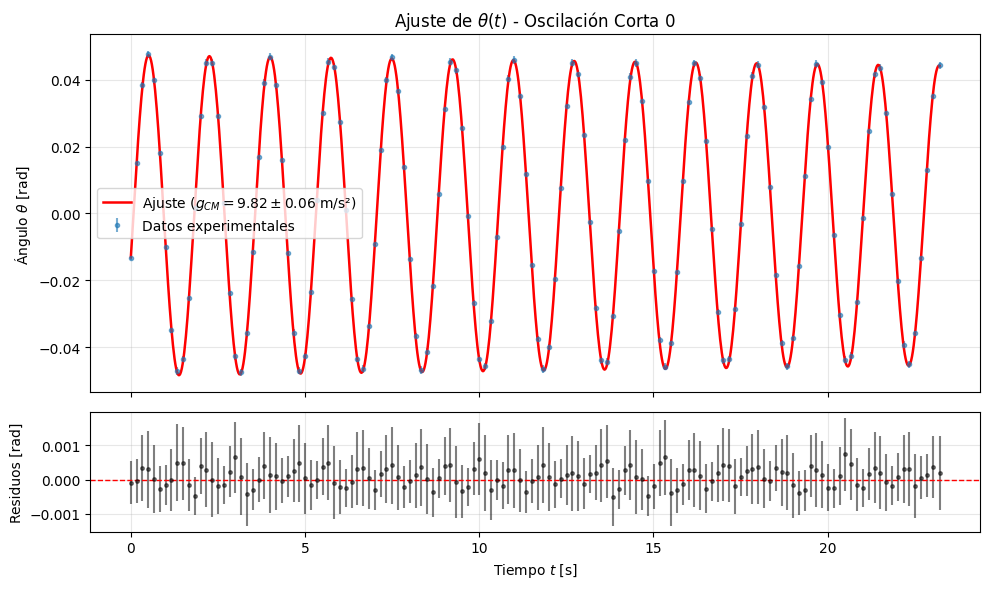

In [39]:
analisis_corta.graficar_ajuste()


In [42]:
exp_corta = GravedadCalculada.desde_video(
    "/content/drive/MyDrive/Videos Recortados/oscilacion#media#0.MOV",
    paso=10
)
exp_corta.imprimir_resumen()
exp_corta.graficar_ajuste()

# Si querés ver o guardar el DataFrame con todas las columnas (t, x, y, X_m, theta_rad, etc.):
exp_corta.df_polar.head()

AttributeError: type object 'GravedadCalculada' has no attribute 'desde_video'

In [ ]:
ruta = "/content/drive/MyDrive/Videos Recortados/oscilacion#media#0.MOV"

# 1. Para correr LA SAMPLEADA (rápida, 1 de cada 10 fotogramas):
exp_sampleado = GravedadCalculada.desde_video_sampleado(ruta, paso=10)
exp_sampleado.imprimir_resumen()
exp_sampleado.graficar_ajuste()

# 2. Para correr LA POSTA (todos los fotogramas + te guarda el .csv en Drive si ponés guardar_csv=True):
#exp_completo = GravedadCalculada.desde_video_completo(ruta, guardar_csv=True)
#exp_completo.imprimir_resumen()
#exp_completo.graficar_ajuste()

In [ ]:
ruta = "/content/drive/MyDrive/Videos Recortados/oscilacion#larga#0.MOV"

# 1. Para correr LA SAMPLEADA (rápida, 1 de cada 10 fotogramas):
exp_sampleado = GravedadCalculada.desde_video_sampleado(ruta, paso=10)
exp_sampleado.imprimir_resumen()


In [47]:
import itertools
from pathlib import Path
import av
import skimage
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2

# ==============================================================================
# 1. CLASE ACTUALIZADA CON ERRORES (X, Y, t), CHI CUADRADO Y AMBOS MODELOS
# ==============================================================================
class GravedadCalculada:
    def __init__(
        self,
        df_polar: pd.DataFrame,
        nombre: str = "Experimento",
        con_amortiguamiento: bool = True,
        largo_base: float = LARGO_PENDULO_BASE,
        largo_sin_base: float = LARGO_PENDULO_SIN_BASE,
        sigma_l: float = SIGMA_L,
        sigma_t: float = SIGMA_T,
    ):
        self.nombre = nombre
        self.con_amortiguamiento = con_amortiguamiento
        self.tipo_modelo = "Con Amort." if con_amortiguamiento else "Sin Amort."
        self.largo_base = largo_base
        self.largo_sin_base = largo_sin_base
        self.largo_cm = 0.5 * (largo_base + largo_sin_base)
        self.sigma_l = sigma_l
        self.sigma_t = sigma_t

        self.df_polar = df_polar
        self.df_fit = df_polar.dropna(
            subset=["t", "theta_rad", "sigma_theta_stat_rad"]
        ).copy()

        self.t_data = self.df_fit["t"].values
        self.y_data = self.df_fit["theta_rad"].values
        # Error estadístico (x, y) punto a punto para el ajuste
        self.y_err_stat = self.df_fit["sigma_theta_stat_rad"].values
        # Error total (incluyendo sistemático de L y escala k)
        self.y_err_total = self.df_fit["sigma_theta_total_rad"].values

        self._ajustar()

    # --- PROCESAMIENTO DE VIDEO ---
    @staticmethod
    def _procesar_fotograma(
        fotograma_gray: np.ndarray,
        recorte_y: tuple[int, int] = (800, 950),
        footprint=skimage.morphology.disk(16),
        umbral: float = 220,
    ) -> tuple[float, float]:
        y_ini, y_fin = recorte_y
        imagen = fotograma_gray.T[y_ini:y_fin]
        imagen = skimage.morphology.closing(imagen, footprint)
        pos = skimage.measure.centroid(imagen < umbral)
        return pos[1], pos[0]  # (x, y)

    @classmethod
    def extraer_xy_video(
        cls,
        archivo: str | Path,
        completo: bool = False,
        paso: int = 10,
        n_fotogramas: int | None = None,
        recorte_y: tuple[int, int] = (800, 950),
        umbral: float = 220,
        radio_disco: int = 16,
    ) -> pd.DataFrame:
        """Extrae (t, x, y) una sola vez para poder ajustar ambos modelos rápido."""
        footprint = skimage.morphology.disk(radio_disco)
        paso_real = 1 if completo else paso
        modo_str = "Completo" if completo else f"Sampleado x{paso}"

        with av.open(archivo) as container:
            video = container.streams.video[0]
            iter_video = container.decode(video=0)
            iter_video = itertools.islice(iter_video, 0, n_fotogramas, paso_real)

            total = None
            if completo and video.frames > 0:
                total = video.frames if n_fotogramas is None else min(video.frames, n_fotogramas)

            data = {"t": [], "x": [], "y": []}
            for fotograma in tqdm(iter_video, total=total, desc=f"[{modo_str}] {Path(archivo).stem}", leave=False):
                x, y = cls._procesar_fotograma(
                    fotograma.to_ndarray(format="gray"),
                    recorte_y=recorte_y,
                    footprint=footprint,
                    umbral=umbral,
                )
                data["t"].append(fotograma.time)
                data["x"].append(x)
                data["y"].append(y)

        return pd.DataFrame(data)

    # --- PASAJE A POLARES USANDO TANTO X COMO Y + PROPAGACIÓN DE ERRORES ---
    @staticmethod
    def xy_a_polar(
        df_xy: pd.DataFrame,
        d_real: float = 0.0450,
        d_px: float = 52.0,
        sigma_d_real: float = SIGMA_C,
        sigma_d_px: float = 1.0,
        sigma_x_px: float = 0.5,
        sigma_y_px: float = 0.5,
        largo_ef: float = 0.5 * (LARGO_PENDULO_BASE + LARGO_PENDULO_SIN_BASE),
        sigma_l: float = SIGMA_L,
        sigma_t: float = SIGMA_T,
    ) -> pd.DataFrame:
        """
        Transforma (x, y) a coordenadas polares (r, theta) propagando:
        - Errores estadísticos punto a punto (sigma_x_px, sigma_y_px) -> para curve_fit y Chi2.
        - Errores sistemáticos de escala (sigma_k) y largo (sigma_L) -> para la incertidumbre total.
        """
        df_p = df_xy.dropna(subset=["t", "x", "y"]).copy()

        # Factor de escala k [m/px] y su error sistemático
        k = d_real / d_px
        sigma_k = k * np.sqrt((sigma_d_real / d_real) ** 2 + (sigma_d_px / d_px) ** 2)

        # Punto de equilibrio (x0, y0) en el punto más bajo de la trayectoria
        x0_px = 0.5 * (df_p["x"].max() + df_p["x"].min())
        # En la imagen y crece hacia abajo: el punto más bajo tiene y máximo
        y0_px = df_p["y"].max()

        dx_px = df_p["x"] - x0_px
        dy_px = y0_px - df_p["y"]  # Elevación vertical positiva hacia arriba [px]

        # Coordenadas cartesianas desde el pivote (X horizontal, Y vertical hacia abajo)
        X_m = dx_px * k
        Y_m = largo_ef - (dy_px * k)
        R_m = np.sqrt(X_m**2 + Y_m**2)

        # Ángulo polar usando AMBAS coordenadas X e Y: theta = arctan2(X, Y)
        df_p["X_m"] = X_m
        df_p["Y_m"] = Y_m
        df_p["R_m"] = R_m
        df_p["theta_rad"] = np.arctan2(X_m, Y_m)
        df_p["theta_deg"] = np.degrees(df_p["theta_rad"])

        # 1. Error ESTADÍSTICO en X e Y (solo debido a la detección del centroide en x e y)
        sigma_X_stat = k * sigma_x_px
        sigma_Y_stat = k * sigma_y_px

        # Derivadas parciales de theta = arctan(X / Y):
        # d(theta)/dX = Y / R^2  ;  d(theta)/dY = -X / R^2
        dtheta_dX = Y_m / (R_m**2)
        dtheta_dY = -X_m / (R_m**2)

        df_p["sigma_theta_stat_rad"] = np.sqrt(
            (dtheta_dX * sigma_X_stat) ** 2 + (dtheta_dY * sigma_Y_stat) ** 2
        )

        # 2. Error TOTAL (sumando errores sistemáticos de escala k y longitud L)
        sigma_X_tot = np.sqrt(sigma_X_stat**2 + (dx_px * sigma_k) ** 2)
        sigma_Y_tot = np.sqrt(sigma_Y_stat**2 + (dy_px * sigma_k) ** 2 + sigma_l**2)

        df_p["sigma_theta_total_rad"] = np.sqrt(
            (dtheta_dX * sigma_X_tot) ** 2 + (dtheta_dY * sigma_Y_tot) ** 2
        )
        df_p["sigma_t"] = sigma_t

        return df_p

    # --- MODELOS MATEMÁTICOS ---
    @staticmethod
    def modelo_amortiguado(t, A, gamma, omega, phi, offset):
        return A * np.exp(-gamma * t) * np.cos(omega * t + phi) + offset

    @staticmethod
    def modelo_sin_amortiguar(t, A, omega, phi, offset):
        return A * np.cos(omega * t + phi) + offset

    def evaluar_modelo(self, t):
        if self.con_amortiguamiento:
            return self.modelo_amortiguado(t, *self.popt)
        return self.modelo_sin_amortiguar(t, *self.popt)

    # --- AJUSTE EN 2 ETAPAS (CON VARIANZA EFECTIVA EN TIEMPO) Y CHI CUADRADO ---
    def _ajustar(self):
        A_init = 0.5 * (self.y_data.max() - self.y_data.min())
        omega_init = np.sqrt(9.8 / self.largo_cm)
        phi_init = 0.0 if self.y_data[0] > np.mean(self.y_data) else np.pi
        offset_init = np.mean(self.y_data)

        if self.con_amortiguamiento:
            func = self.modelo_amortiguado
            p0 = [A_init, 0.003, omega_init, phi_init, offset_init]
        else:
            func = self.modelo_sin_amortiguar
            p0 = [A_init, omega_init, phi_init, offset_init]

        # Etapa 1: Ajuste preliminar con error estadístico de (x, y)
        popt_1, _ = curve_fit(
            func, self.t_data, self.y_data, p0=p0,
            sigma=self.y_err_stat, absolute_sigma=True, maxfev=10000
        )

        # Etapa 2: Propagamos el error de frame/obturación temporal (sigma_t_frame)
        # Durante la exposición de un fotograma (~1/(2*fps)), el movimiento borroso aporta error
        sigma_t_ef = 0.25 * self.sigma_t
        if self.con_amortiguamiento:
            A_1, gamma_1, omega_1, phi_1, _ = popt_1
            dtheta_dt = -A_1 * np.exp(-gamma_1 * self.t_data) * omega_1 * np.sin(omega_1 * self.t_data + phi_1)
        else:
            A_1, omega_1, phi_1, _ = popt_1
            dtheta_dt = -A_1 * omega_1 * np.sin(omega_1 * self.t_data + phi_1)

        self.y_err_ef = np.sqrt(self.y_err_stat**2 + (dtheta_dt * sigma_t_ef) ** 2)

        # Ajuste definitivo ponderado con la varianza efectiva total punto a punto
        self.popt, self.pcov = curve_fit(
            func, self.t_data, self.y_data, p0=popt_1,
            sigma=self.y_err_ef, absolute_sigma=True, maxfev=10000
        )
        perr = np.sqrt(np.diag(self.pcov))

        if self.con_amortiguamiento:
            A_fit, gamma_fit, omega_fit, phi_fit, offset_fit = self.popt
            sigma_A, sigma_gamma, sigma_omega, sigma_phi, sigma_offset = perr
        else:
            A_fit, omega_fit, phi_fit, offset_fit = self.popt
            sigma_A, sigma_omega, sigma_phi, sigma_offset = perr
            gamma_fit, sigma_gamma = 0.0, 0.0

        # Normalizamos signos de amplitud y frecuencia
        if A_fit < 0:
            A_fit = -A_fit
            phi_fit = (phi_fit + np.pi) % (2 * np.pi)
        omega_fit = np.abs(omega_fit)

        if self.con_amortiguamiento:
            self.popt = [A_fit, gamma_fit, omega_fit, phi_fit, offset_fit]
        else:
            self.popt = [A_fit, omega_fit, phi_fit, offset_fit]

        self.A, self.sigma_A = A_fit, sigma_A
        self.gamma, self.sigma_gamma = gamma_fit, sigma_gamma
        self.omega, self.sigma_omega = omega_fit, sigma_omega
        self.phi, self.sigma_phi = phi_fit, sigma_phi
        self.offset, self.sigma_offset = offset_fit, sigma_offset

        # Frecuencia natural omega_0 y Período T
        self.omega_0 = np.sqrt(self.omega**2 + self.gamma**2)
        self.sigma_omega_0 = (
            np.sqrt((self.omega * self.sigma_omega) ** 2 + (self.gamma * self.sigma_gamma) ** 2)
            / self.omega_0
        )
        self.T = (2.0 * np.pi) / self.omega
        self.sigma_T = ((2.0 * np.pi) / (self.omega**2)) * self.sigma_omega

        # Cálculo de Chi cuadrado y grados de libertad
        self.residuos = self.y_data - self.evaluar_modelo(self.t_data)
        self.chi2 = np.sum((self.residuos / self.y_err_ef) ** 2)
        self.dof = len(self.y_data) - len(self.popt)
        self.chi2_red = self.chi2 / self.dof
        self.p_valor = 1.0 - chi2.cdf(self.chi2, self.dof)

        # Gravedad en el centro de masa (acá entra el error sistemático sigma_L)
        self.g, self.sigma_g = self.calcular_g(self.largo_cm)

    def calcular_g(self, valor_L: float) -> tuple[float, float]:
        g_val = valor_L * (self.omega_0**2)
        sigma_g_val = g_val * np.sqrt(
            (self.sigma_l / valor_L) ** 2 + (2.0 * self.sigma_omega_0 / self.omega_0) ** 2
        )
        return g_val, sigma_g_val

    def diccionario_resumen(self) -> dict:
        g_base, _ = self.calcular_g(self.largo_base)
        g_sin, _ = self.calcular_g(self.largo_sin_base)
        return {
            "Video": self.nombre,
            "Modelo": self.tipo_modelo,
            "θ_max [°]": np.degrees(self.A),
            "ω [rad/s]": self.omega,
            "σ_ω [rad/s]": self.sigma_omega,
            "T [s]": self.T,
            "σ_T [s]": self.sigma_T,
            "γ [1/s]": self.gamma,
            "σ_γ [1/s]": self.sigma_gamma,
            "χ²": self.chi2,
            "ν (dof)": self.dof,
            "χ²_red": self.chi2_red,
            "g_CM [m/s²]": self.g,
            "σ_g_CM [m/s²]": self.sigma_g,
            "g_sin_base": g_sin,
            "g_con_base": g_base,
        }



In [48]:

# ==============================================================================
# 2. CONFIGURACIÓN DE TUS 3 VIDEOS (CHICO, MEDIO, LARGO)
# ==============================================================================
carpeta = Path("/content/drive/MyDrive/Videos Recortados")

# Ajustá los nombres de archivo si tu video de ángulo medio se llama distinto:
VIDEOS = {
    "Ángulo Chico": carpeta / "oscilacion#corta#0.MOV",
    "Ángulo Medio": carpeta / "oscilacion#media#0.MOV",
    "Ángulo Largo": carpeta / "oscilacion#larga#0.MOV",
}

# Si algún nombre no coincide exactamente, buscamos automáticamente los .MOV disponibles
archivos_existentes = {k: v for k, v in VIDEOS.items() if v.exists()}
if len(archivos_existentes) < 3:
    todos_mov = sorted([f for f in carpeta.glob("*.MOV") if "Fondo" not in f.name])
    print("Videos encontrados automáticamente en la carpeta:", [f.name for f in todos_mov])
    VIDEOS = {f.stem: f for f in todos_mov[:3]}

# Poné USAR_COMPLETO = True para usar todos los fotogramas ("la posta")
USAR_COMPLETO = False
PASO_SAMPLEO = 10

resultados_amort = {}
resultados_sin_amort = {}
filas_tabla = []




Extrayendo datos de: Ángulo Chico (oscilacion#corta#0.MOV)...


[Sampleado x10] oscilacion#corta#0: 0it [00:00, ?it/s]

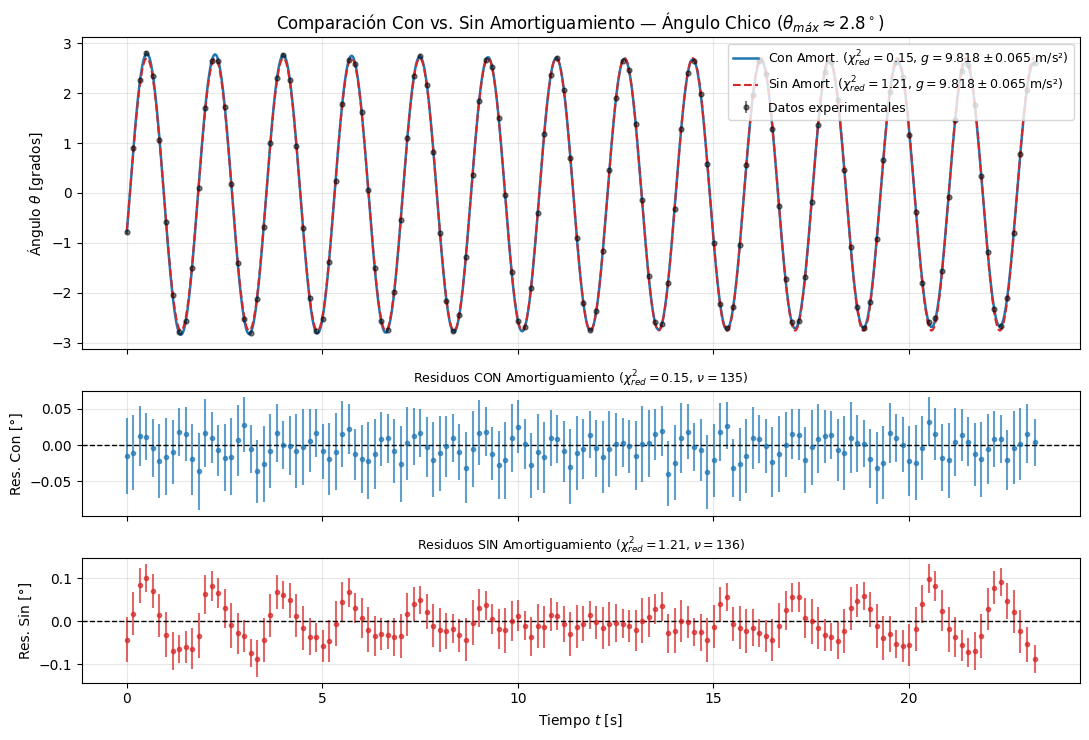


Extrayendo datos de: Ángulo Medio (oscilacion#media#0.MOV)...


[Sampleado x10] oscilacion#media#0: 0it [00:00, ?it/s]

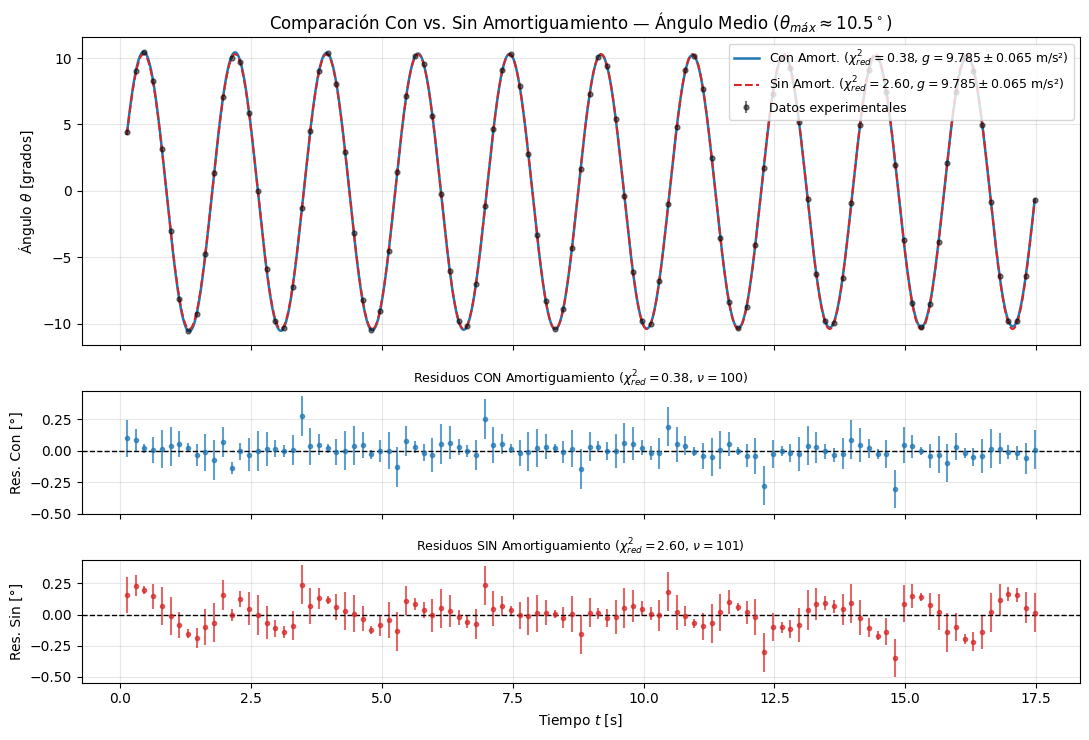


Extrayendo datos de: Ángulo Largo (oscilacion#larga#0.MOV)...


[Sampleado x10] oscilacion#larga#0: 0it [00:00, ?it/s]

/usr/local/lib/python3.13/dist-packages/skimage/measure/_moments.py:401: RuntimeWarning: invalid value encountered in divide
  M[tuple(np.eye(image.ndim, dtype=int))]  # array of weighted sums


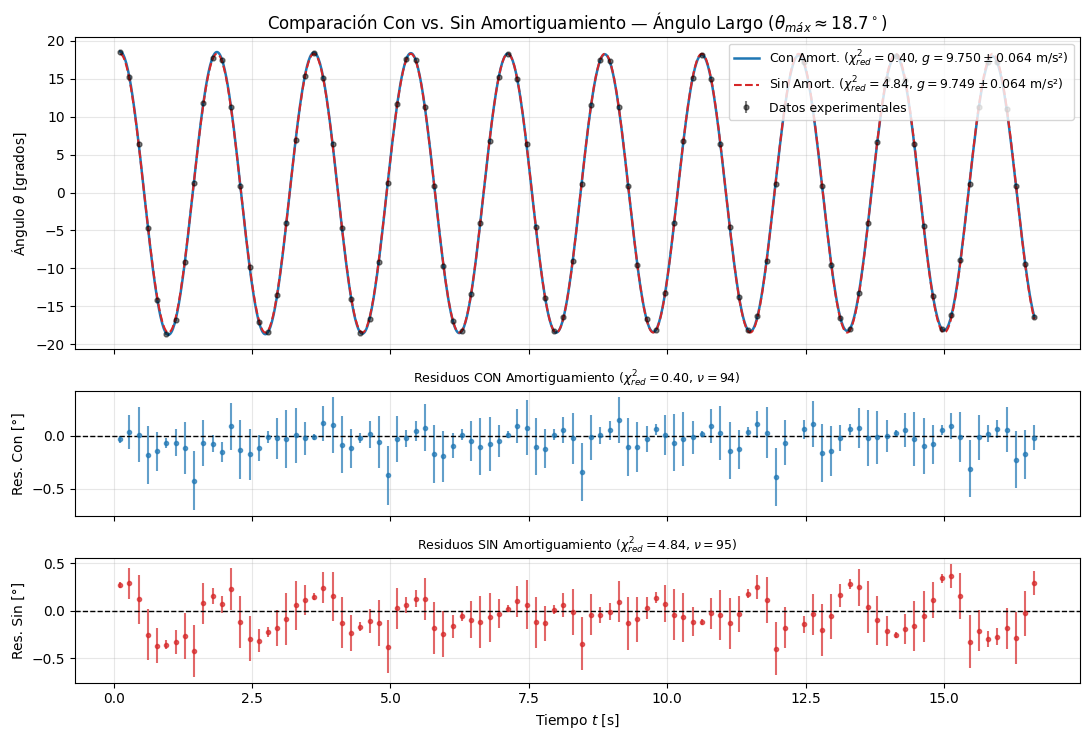

In [49]:
# ==============================================================================
# 3. EJECUCIÓN Y PUNTO 1: COMPARAR CON Y SIN AMORTIGUAMIENTO EN CADA VIDEO
# ==============================================================================
for etiqueta, ruta_video in VIDEOS.items():
    print(f"\nExtrayendo datos de: {etiqueta} ({ruta_video.name})...")
    df_xy = GravedadCalculada.extraer_xy_video(
        ruta_video, completo=USAR_COMPLETO, paso=PASO_SAMPLEO
    )
    df_polar = GravedadCalculada.xy_a_polar(df_xy)

    # Creamos ambas versiones (Con y Sin amortiguamiento) sobre los mismos datos
    exp_con = GravedadCalculada(df_polar, nombre=etiqueta, con_amortiguamiento=True)
    exp_sin = GravedadCalculada(df_polar, nombre=etiqueta, con_amortiguamiento=False)

    resultados_amort[etiqueta] = exp_con
    resultados_sin_amort[etiqueta] = exp_sin
    filas_tabla.append(exp_con.diccionario_resumen())
    filas_tabla.append(exp_sin.diccionario_resumen())

    # --- GRÁFICO INDIVIDUAL: CON vs SIN AMORTIGUAMIENTO Y SUS RESIDUOS ---
    t_suave = np.linspace(exp_con.t_data.min(), exp_con.t_data.max(), 1200)
    fig, (ax1, ax2, ax3) = plt.subplots(
        3, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.2, 1.2]}
    )

    # Panel superior: Datos y ambos ajustes
    ax1.errorbar(
        exp_con.t_data, np.degrees(exp_con.y_data), yerr=np.degrees(exp_con.y_err_ef),
        fmt="o", markersize=3.5, color="black", alpha=0.5, label="Datos experimentales"
    )
    ax1.plot(
        t_suave, np.degrees(exp_con.evaluar_modelo(t_suave)), color="C0", lw=1.8,
        label=f"Con Amort. ($\\chi^2_{{red}} = {exp_con.chi2_red:.2f}$, $g = {exp_con.g:.3f}\\pm{exp_con.sigma_g:.3f}$ m/s²)"
    )
    ax1.plot(
        t_suave, np.degrees(exp_sin.evaluar_modelo(t_suave)), color="C3", linestyle="--", lw=1.5,
        label=f"Sin Amort. ($\\chi^2_{{red}} = {exp_sin.chi2_red:.2f}$, $g = {exp_sin.g:.3f}\\pm{exp_sin.sigma_g:.3f}$ m/s²)"
    )
    ax1.set_ylabel(r"Ángulo $\theta$ [grados]")
    ax1.set_title(f"Comparación Con vs. Sin Amortiguamiento — {etiqueta} ($\\theta_{{máx}} \\approx {np.degrees(exp_con.A):.1f}^\\circ$)")
    ax1.legend(loc="upper right", fontsize=9)
    ax1.grid(True, alpha=0.3)

    # Panel medio: Residuos CON amortiguamiento
    ax2.errorbar(
        exp_con.t_data, np.degrees(exp_con.residuos), yerr=np.degrees(exp_con.y_err_ef),
        fmt="o", markersize=3, color="C0", alpha=0.7
    )
    ax2.axhline(0, color="black", linestyle="--", lw=1)
    ax2.set_ylabel("Res. Con [°]")
    ax2.set_title(f"Residuos CON Amortiguamiento ($\\chi^2_{{red}} = {exp_con.chi2_red:.2f}$, $\\nu = {exp_con.dof}$)", fontsize=9)
    ax2.grid(True, alpha=0.3)

    # Panel inferior: Residuos SIN amortiguamiento
    ax3.errorbar(
        exp_sin.t_data, np.degrees(exp_sin.residuos), yerr=np.degrees(exp_sin.y_err_ef),
        fmt="o", markersize=3, color="C3", alpha=0.7
    )
    ax3.axhline(0, color="black", linestyle="--", lw=1)
    ax3.set_ylabel("Res. Sin [°]")
    ax3.set_xlabel("Tiempo $t$ [s]")
    ax3.set_title(f"Residuos SIN Amortiguamiento ($\\chi^2_{{red}} = {exp_sin.chi2_red:.2f}$, $\\nu = {exp_sin.dof}$)", fontsize=9)
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()





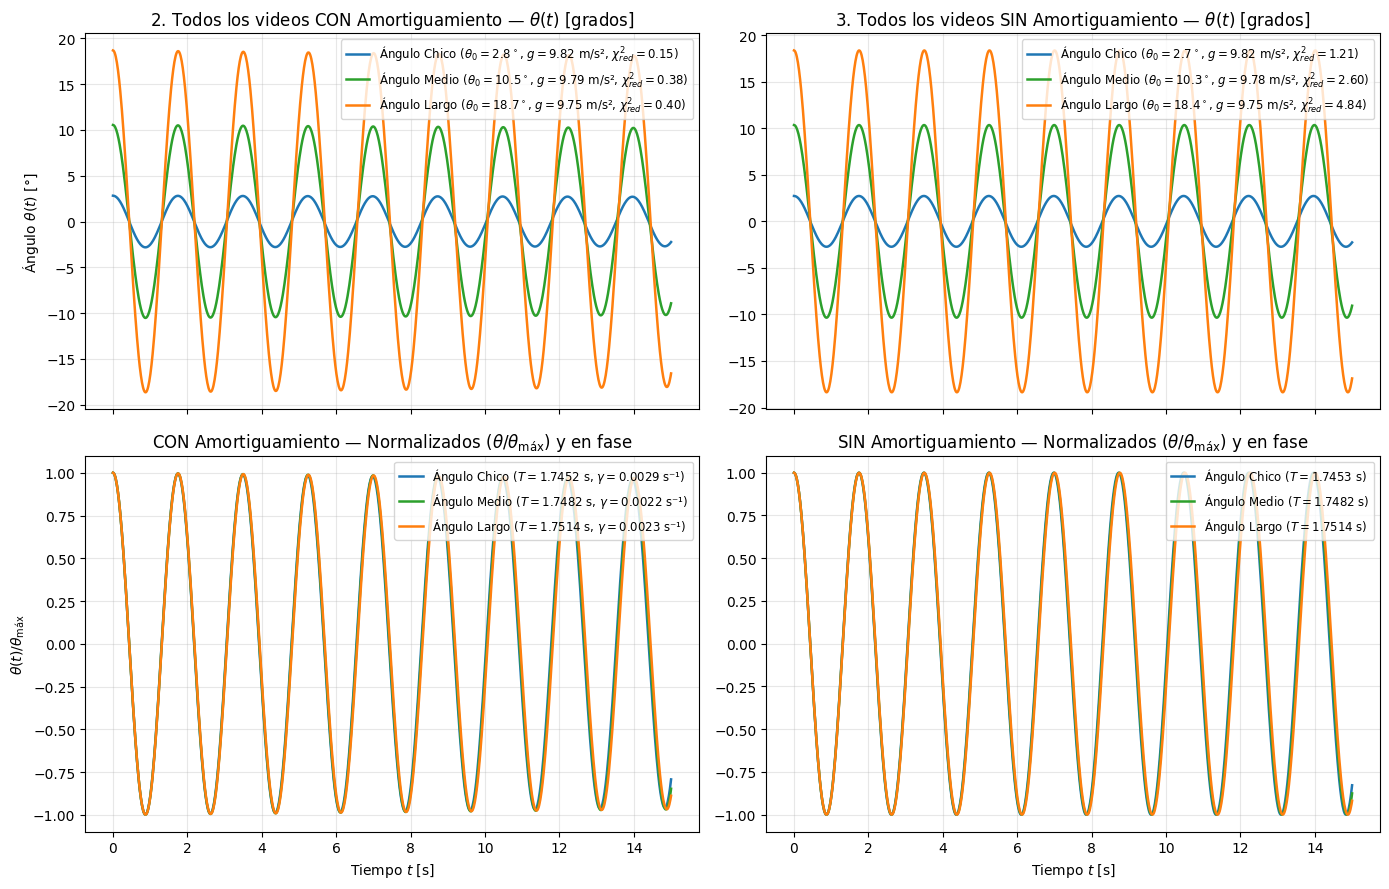

In [50]:

# ==============================================================================
# 4. PUNTOS 2 Y 3: COMPARAR TODOS LOS VIDEOS JUNTOS (CON Y SIN AMORTIGUAR)
# ==============================================================================
t_comun = np.linspace(0, 15, 1000)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
(ax_con_real, ax_sin_real), (ax_con_norm, ax_sin_norm) = axes

colores = ["C0", "C2", "C1"]

for idx, etiqueta in enumerate(resultados_amort.keys()):
    c = colores[idx % len(colores)]
    e_con = resultados_amort[etiqueta]
    e_sin = resultados_sin_amort[etiqueta]

    # --- PUNTO 2: TODOS CON AMORTIGUAMIENTO ---
    # Curva en grados (alineada en fase inicial phi=0 para comparar visualmente)
    curva_con_deg = np.degrees(e_con.A * np.exp(-e_con.gamma * t_comun) * np.cos(e_con.omega * t_comun))
    curva_con_norm = np.exp(-e_con.gamma * t_comun) * np.cos(e_con.omega * t_comun)

    ax_con_real.plot(
        t_comun, curva_con_deg, color=c, lw=1.8,
        label=f"{etiqueta} ($\\theta_0={np.degrees(e_con.A):.1f}^\\circ$, $g={e_con.g:.2f}$ m/s², $\\chi^2_{{red}}={e_con.chi2_red:.2f}$)"
    )
    ax_con_norm.plot(
        t_comun, curva_con_norm, color=c, lw=1.8,
        label=f"{etiqueta} ($T={e_con.T:.4f}$ s, $\\gamma={e_con.gamma:.4f}$ s⁻¹)"
    )

    # --- PUNTO 3: TODOS SIN AMORTIGUAMIENTO ---
    curva_sin_deg = np.degrees(e_sin.A * np.cos(e_sin.omega * t_comun))
    curva_sin_norm = np.cos(e_sin.omega * t_comun)

    ax_sin_real.plot(
        t_comun, curva_sin_deg, color=c, lw=1.8,
        label=f"{etiqueta} ($\\theta_0={np.degrees(e_sin.A):.1f}^\\circ$, $g={e_sin.g:.2f}$ m/s², $\\chi^2_{{red}}={e_sin.chi2_red:.2f}$)"
    )
    ax_sin_norm.plot(
        t_comun, curva_sin_norm, color=c, lw=1.8,
        label=f"{etiqueta} ($T={e_sin.T:.4f}$ s)"
    )

ax_con_real.set_title("2. Todos los videos CON Amortiguamiento — $\\theta(t)$ [grados]")
ax_con_real.set_ylabel(r"Ángulo $\theta(t)$ [°]")
ax_con_real.legend(loc="upper right", fontsize=8.5)
ax_con_real.grid(True, alpha=0.3)

ax_sin_real.set_title("3. Todos los videos SIN Amortiguamiento — $\\theta(t)$ [grados]")
ax_sin_real.legend(loc="upper right", fontsize=8.5)
ax_sin_real.grid(True, alpha=0.3)

ax_con_norm.set_title("CON Amortiguamiento — Normalizados ($\\theta / \\theta_{\\mathrm{máx}}$) y en fase")
ax_con_norm.set_ylabel(r"$\theta(t) / \theta_{\mathrm{máx}}$")
ax_con_norm.set_xlabel("Tiempo $t$ [s]")
ax_con_norm.legend(loc="upper right", fontsize=8.5)
ax_con_norm.grid(True, alpha=0.3)

ax_sin_norm.set_title("SIN Amortiguamiento — Normalizados ($\\theta / \\theta_{\\mathrm{máx}}$) y en fase")
ax_sin_norm.set_xlabel("Tiempo $t$ [s]")
ax_sin_norm.legend(loc="upper right", fontsize=8.5)
ax_sin_norm.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
# ==============================================================================
# 5. PUNTO 4: TABLA RESUMEN CON CHI CUADRADO, PERÍODOS Y GRAVEDAD
# ==============================================================================
df_resultados_final = pd.DataFrame(filas_tabla)
pd.set_option("display.float_format", "{:.4f}".format)
display(df_resultados_final)

,Video,Modelo,θ_max [°],ω [rad/s],σ_ω [rad/s],T [s],σ_T [s],γ [1/s],σ_γ [1/s],χ²,ν (dof),χ²_red,g_CM [m/s²],σ_g_CM [m/s²],g_sin_base,g_con_base
0,Ángulo Chico,Con Amort.,2.8232,3.6002,0.0003,1.7452,0.0001,0.0029,0.0002,19.9615,135,0.1479,9.8183,0.0648,9.5526,10.0840
1,Ángulo Chico,Sin Amort.,2.7285,3.6001,0.0003,1.7453,0.0001,0.0000,0.0000,164.7249,136,1.2112,9.8179,0.0648,9.5522,10.0836
2,Ángulo Medio,Con Amort.,10.5456,3.5941,0.0003,1.7482,0.0002,0.0022,0.0001,38.3440,100,0.3834,9.7851,0.0646,9.5203,10.0499
3,Ángulo Medio,Sin Amort.,10.3480,3.5941,0.0003,1.7482,0.0002,0.0000,0.0000,262.8045,101,2.6020,9.7848,0.0646,9.5200,10.0496
4,Ángulo Largo,Con Amort.,18.6885,3.5876,0.0003,1.7514,0.0002,0.0023,0.0001,37.9950,94,0.4042,9.7498,0.0644,9.4860,10.0137
5,Ángulo Largo,Sin Amort.,18.3655,3.5875,0.0003,1.7514,0.0002,0.0000,0.0000,459.6308,95,4.8382,9.7491,0.0644,9.4852,10.0129


  1. ¿A PARTIR DE QUÉ ÁNGULO DEJA DE CUMPLIRSE EL OSCILADOR ARMÓNICO?
Período armónico base estimado (θ -> 0): T0 = (1.74497 ± 0.00015) s
 • Límite de detección de TU experimento (ΔT > σ_T): θ_crít = 2.1°
   (A partir de 2.1°, la desviación respecto al M.A.S. supera la barra de error σ_T)
 • Desviación teórica del 0.1% en el período:       θ = 7.2°
 • Desviación teórica del 0.5% en el período:       θ = 16.2°
 • Desviación teórica del 1.0% en el período:       θ = 22.9°

  2. ¿EL AMORTIGUAMIENTO REALMENTE AFECTA O NO?


,Video,θ_inicial [°],γ ± σ_γ [1/s],Significancia γ (γ/σ_γ),Caída Amplitud [%],χ²_red (Con Amort.),χ²_red (Sin Amort.),|T_con - T_sin| [s],Efecto de γ en T [ppm],p-valor (Test F)
0,Ángulo Chico,2.8232,0.00293 ± 0.00024,12.0211,6.5676,0.1479,1.2112,0.0000,0.3304,0.0000
1,Ángulo Medio,10.5456,0.00221 ± 0.00015,14.9958,3.7584,0.3834,2.6020,0.0000,0.1888,0.0000
2,Ángulo Largo,18.6885,0.00226 ± 0.00011,20.5458,3.6646,0.4042,4.8382,0.0001,0.1986,0.0000


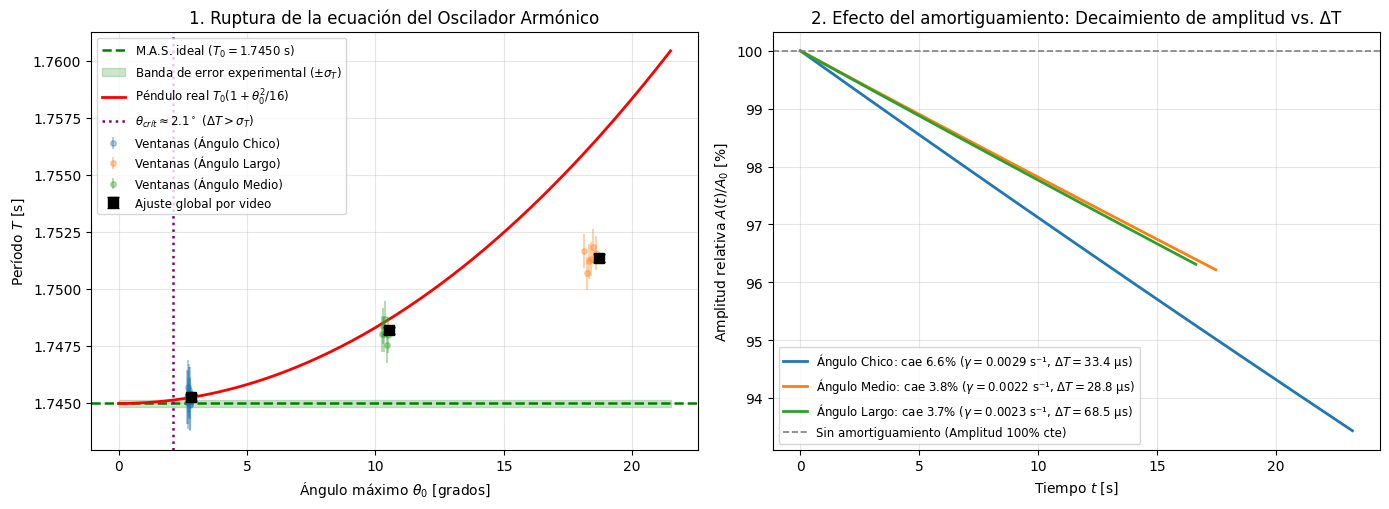

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import f as f_dist

# ==============================================================================
# 1. FUNCIÓN PARA ANALIZAR VENTANAS TEMPORALES (BARRIDO CONTINUO DE ÁNGULOS)
# ==============================================================================
def analizar_por_ventanas(df_polar, nombre_video, duracion_ventana=6.0, paso_ventana=2.0):
    """
    Divide un video en tramos cortos para medir cómo varía el período T(theta)
    a medida que decae la amplitud, más allá de tener solo 3 videos.
    """
    df_clean = df_polar.dropna(subset=["t", "theta_rad", "sigma_theta_stat_rad"]).copy()
    t_min, t_max = df_clean["t"].min(), df_clean["t"].max()

    puntos_ventana = []
    t_ini = t_min
    while t_ini + duracion_ventana <= t_max:
        sub_df = df_clean[(df_clean["t"] >= t_ini) & (df_clean["t"] <= t_ini + duracion_ventana)]
        if len(sub_df) >= 15:  # Mínimo de puntos para ajustar la ventana
            try:
                exp_v = GravedadCalculada(sub_df, nombre=f"{nombre_video}_v", con_amortiguamiento=False)
                # Filtramos ajustes con errores razonables
                if exp_v.sigma_T < 0.02:
                    puntos_ventana.append({
                        "Video": nombre_video,
                        "t_medio [s]": t_ini + 0.5 * duracion_ventana,
                        "θ_max [°]": np.degrees(exp_v.A),
                        "θ_max [rad]": exp_v.A,
                        "T [s]": exp_v.T,
                        "σ_T [s]": exp_v.sigma_T,
                        "ω [rad/s]": exp_v.omega,
                        "σ_ω [rad/s]": exp_v.sigma_omega,
                    })
            except Exception:
                pass
        t_ini += paso_ventana
    return pd.DataFrame(puntos_ventana)


# ==============================================================================
# 2. COMPARACIÓN CON vs. SIN AMORTIGUAMIENTO Y EXTRACCIÓN DE VENTANAS
# ==============================================================================
filas_amortiguamiento = []
lista_ventanas = []

for etiqueta in resultados_amort.keys():
    e_con = resultados_amort[etiqueta]
    e_sin = resultados_sin_amort[etiqueta]

    # Caída porcentual de amplitud de punta a punta del video
    duracion_video = e_con.t_data.max() - e_con.t_data.min()
    caida_amp_pct = (1.0 - np.exp(-e_con.gamma * duracion_video)) * 100.0

    # Cambio relativo en frecuencia por culpa del amortiguamiento: (omega_0 - omega) / omega_0
    corrimiento_freq_ppm = ((e_con.omega_0 - e_con.omega) / e_con.omega_0) * 1e6  # en partes por millón (ppm)
    diff_T_modelos = np.abs(e_con.T - e_sin.T)

    # Test F de Fisher para ver si agregar el parámetro gamma mejora significativamente el ajuste
    # F = ((Chi2_sin - Chi2_con) / (dof_sin - dof_con)) / (Chi2_con / dof_con)
    delta_chi2 = max(0.0, e_sin.chi2 - e_con.chi2)
    f_stat = (delta_chi2 / 1.0) / e_con.chi2_red
    p_val_f = 1.0 - f_dist.cdf(f_stat, 1, e_con.dof)

    filas_amortiguamiento.append({
        "Video": etiqueta,
        "θ_inicial [°]": np.degrees(e_con.A),
        "γ ± σ_γ [1/s]": f"{e_con.gamma:.5f} ± {e_con.sigma_gamma:.5f}",
        "Significancia γ (γ/σ_γ)": e_con.gamma / e_con.sigma_gamma if e_con.sigma_gamma > 0 else np.nan,
        "Caída Amplitud [%]": caida_amp_pct,
        "χ²_red (Con Amort.)": e_con.chi2_red,
        "χ²_red (Sin Amort.)": e_sin.chi2_red,
        "|T_con - T_sin| [s]": diff_T_modelos,
        "Efecto de γ en T [ppm]": corrimiento_freq_ppm,
        "p-valor (Test F)": p_val_f,
    })

    # Extraemos ventanas si el video tiene suficientes puntos
    df_vent = analizar_por_ventanas(e_con.df_polar, etiqueta)
    if not df_vent.empty:
        lista_ventanas.append(df_vent)

df_estudio_amort = pd.DataFrame(filas_amortiguamiento).sort_values("θ_inicial [°]")


# ==============================================================================
# 3. CÁLCULO DEL ÁNGULO CRÍTICO DONDE FALLA EL OSCILADOR ARMÓNICO SIMPLE
# ==============================================================================
# Tomamos el video de menor ángulo como referencia del régimen armónico (T0)
exp_chico = min(resultados_amort.values(), key=lambda x: x.A)
# Corrección inversa de Borda para estimar T0 puro a ángulo -> 0
T0_est = exp_chico.T / (1.0 + (exp_chico.A ** 2) / 16.0)
sigma_T_exp = exp_chico.sigma_T

# 1) Ángulo crítico experimental: cuando el término (theta^2 / 16) supera el error sigma_T / T0
theta_crit_exp_rad = np.sqrt(16.0 * (sigma_T_exp / T0_est))
theta_crit_exp_deg = np.degrees(theta_crit_exp_rad)

# 2) Ángulos críticos teóricos según tolerancia porcentual típica (0.1%, 0.5%, 1%)
theta_crit_01pct = np.degrees(np.sqrt(16.0 * 0.001))  # 0.1% de error en T
theta_crit_05pct = np.degrees(np.sqrt(16.0 * 0.005))  # 0.5% de error en T
theta_crit_10pct = np.degrees(np.sqrt(16.0 * 0.010))  # 1.0% de error en T

print("======================================================================")
print("  1. ¿A PARTIR DE QUÉ ÁNGULO DEJA DE CUMPLIRSE EL OSCILADOR ARMÓNICO?")
print("======================================================================")
print(f"Período armónico base estimado (θ -> 0): T0 = ({T0_est:.5f} ± {sigma_T_exp:.5f}) s")
print(f" • Límite de detección de TU experimento (ΔT > σ_T): θ_crít = {theta_crit_exp_deg:.1f}°")
print(f"   (A partir de {theta_crit_exp_deg:.1f}°, la desviación respecto al M.A.S. supera la barra de error σ_T)")
print(f" • Desviación teórica del 0.1% en el período:       θ = {theta_crit_01pct:.1f}°")
print(f" • Desviación teórica del 0.5% en el período:       θ = {theta_crit_05pct:.1f}°")
print(f" • Desviación teórica del 1.0% en el período:       θ = {theta_crit_10pct:.1f}°\n")

print("======================================================================")
print("  2. ¿EL AMORTIGUAMIENTO REALMENTE AFECTA O NO?")
print("======================================================================")
display(df_estudio_amort)


# ==============================================================================
# 4. GRÁFICOS DEMOSTRATIVOS PARA EL INFORME
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# --- Panel 1: Ruptura del Oscilador Armónico T(θ) vs T0 ---
theta_deg_grid = np.linspace(0, max(np.degrees(e.A) for e in resultados_amort.values()) * 1.15, 300)
theta_rad_grid = np.radians(theta_deg_grid)

# Curva constante del Oscilador Armónico Simple (M.A.S.) y su banda de incerteza
ax1.axhline(T0_est, color="green", linestyle="--", lw=1.8, label=f"M.A.S. ideal ($T_0 = {T0_est:.4f}$ s)")
ax1.fill_between(
    theta_deg_grid, T0_est - sigma_T_exp, T0_est + sigma_T_exp,
    color="green", alpha=0.2, label=r"Banda de error experimental ($\pm \sigma_T$)"
)

# Curva anarmónica teórica (Borda): T(θ) = T0 * (1 + θ²/16 + 11θ⁴/3072)
T_borda = T0_est * (1.0 + (theta_rad_grid**2) / 16.0 + (11.0 * (theta_rad_grid**4)) / 3072.0)
ax1.plot(theta_deg_grid, T_borda, color="red", lw=2, label=r"Péndulo real $T_0(1 + \theta_0^2/16)$")

# Puntos de ventanas temporales (si hay suficientes frames)
if lista_ventanas:
    df_todas_vent = pd.concat(lista_ventanas, ignore_index=True)
    for vid_name, grp in df_todas_vent.groupby("Video"):
        ax1.errorbar(
            grp["θ_max [°]"], grp["T [s]"], yerr=grp["σ_T [s]"],
            fmt="o", markersize=4, alpha=0.35, label=f"Ventanas ({vid_name})"
        )

# Puntos globales de los 3 videos
thetas_glob = [np.degrees(e.A) for e in resultados_amort.values()]
T_glob = [e.T for e in resultados_amort.values()]
sT_glob = [e.sigma_T for e in resultados_amort.values()]
ax1.errorbar(
    thetas_glob, T_glob, yerr=sT_glob,
    fmt="s", markersize=7, color="black", capsize=4, zorder=5, label="Ajuste global por video"
)

# Línea vertical marcando el ángulo crítico experimental
ax1.axvline(theta_crit_exp_deg, color="purple", linestyle=":", lw=1.8,
            label=f"$\\theta_{{crít}} \\approx {theta_crit_exp_deg:.1f}^\\circ$ ($\\Delta T > \\sigma_T$)")

ax1.set_xlabel(r"Ángulo máximo $\theta_0$ [grados]")
ax1.set_ylabel("Período $T$ [s]")
ax1.set_title("1. Ruptura de la ecuación del Oscilador Armónico")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.grid(True, alpha=0.3)

# --- Panel 2: Efecto del Amortiguamiento (Decaimiento de Amplitud vs Frecuencia) ---
for idx, (etiqueta, e_con) in enumerate(resultados_amort.items()):
    e_sin = resultados_sin_amort[etiqueta]
    t_vec = np.linspace(0, e_con.t_data.max(), 200)

    # Envolvente exponencial normalizada: A(t) / A(0) = exp(-gamma * t)
    envolvente = np.exp(-e_con.gamma * t_vec) * 100.0
    ax2.plot(
        t_vec, envolvente, lw=2,
        label=f"{etiqueta}: cae {100 - envolvente[-1]:.1f}% ($\\gamma={e_con.gamma:.4f}$ s⁻¹, $\\Delta T = {np.abs(e_con.T - e_sin.T)*1e6:.1f}$ µs)"
    )

ax2.axhline(100.0, color="gray", linestyle="--", lw=1.2, label="Sin amortiguamiento (Amplitud 100% cte)")
ax2.set_xlabel("Tiempo $t$ [s]")
ax2.set_ylabel("Amplitud relativa $A(t) / A_0$ [%]")
ax2.set_title("2. Efecto del amortiguamiento: Decaimiento de amplitud vs. ΔT")
ax2.legend(loc="lower left", fontsize=8.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Videos usados: Ángulo Chico, Ángulo Medio, Ángulo Largo
Incertezas: heredada (provisionales; mismas para ambos modelos).
Hipótesis: mismo péndulo y longitud en todos los videos.
Ajustando modelo: lineal
Ajustando modelo: seno


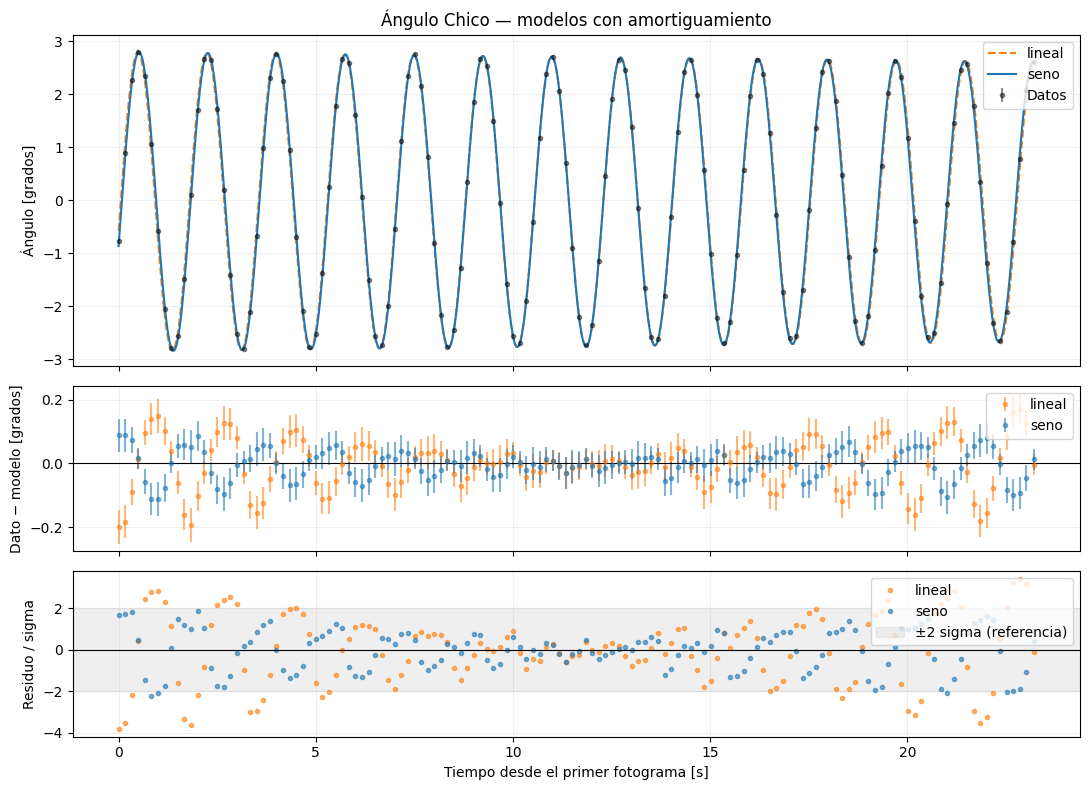

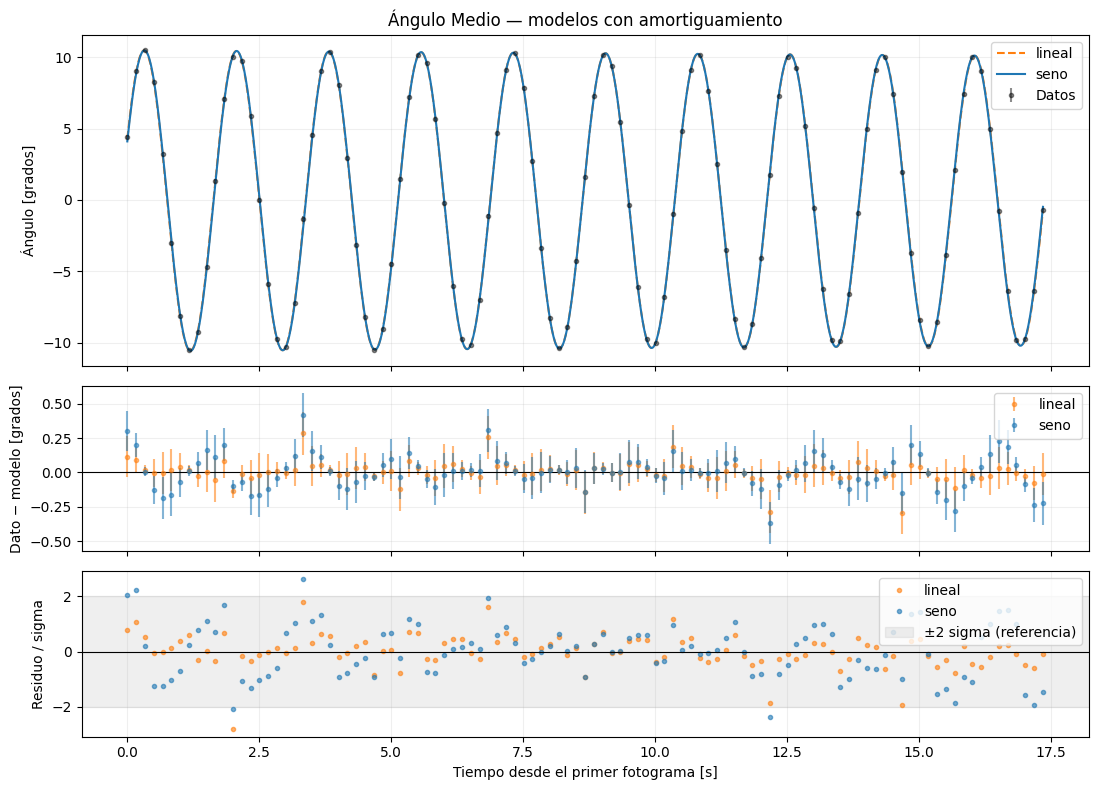

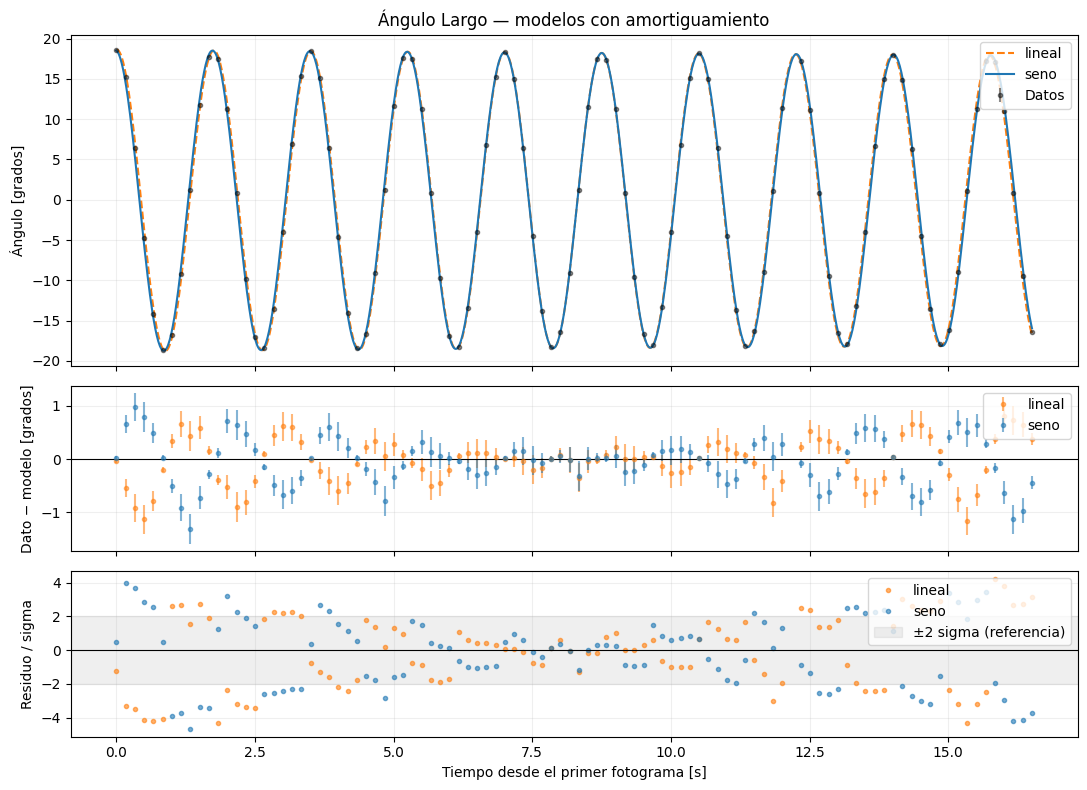


COMPARACIÓN GLOBAL (pesos provisionales)
Modelo  omega0 [rad/s]   N  Parametros    chi2  Grados de libertad  chi2 reducido  AIC (constante omitida)
lineal         3.59434 344          13 864.331                 331        2.61127                  890.331
  seno         3.60405 344          13 673.842                 331        2.03578                  699.842

RESIDUOS POR VIDEO
       Video  Semirango observado [grados]  RMS residuo lineal [grados]  chi2/N lineal  RMS residuo seno [grados]  chi2/N seno  Delta chi2 (lineal - seno)
Ángulo Chico                       2.80064                    0.0785166        2.74419                  0.0463213     0.988445                     245.804
Ángulo Medio                       10.4957                    0.0725576       0.369815                   0.123022     0.973865                    -63.4253
Ángulo Largo                       18.6058                     0.425486        4.45772                   0.440267       4.3758                     8.109

In [53]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares


def trayectoria(t, omega0, parametros, modelo):
    """t empieza en cero; parámetros: theta_i [rad], v_i [rad/s], gamma [1/s], offset [rad]."""
    theta_i, v_i, gamma, offset = parametros
    t = np.asarray(t, dtype=float)
    if modelo not in ('lineal', 'seno'):
        raise ValueError('Modelo desconocido.')

    def ecuacion(_, estado):
        theta, v = estado
        restauracion = theta if modelo == 'lineal' else np.sin(theta)
        return (v, -2 * gamma * v - omega0**2 * restauracion)

    sol = solve_ivp(ecuacion, (0.0, float(t[-1])), (theta_i, v_i),
                    t_eval=t, method='DOP853', rtol=2e-9, atol=2e-11)
    if not sol.success or sol.y.shape[1] != len(t):
        raise RuntimeError('Falló la integración: ' + sol.message)
    return sol.y[0] + offset


def preparar_datos(experimentos, incertidumbre='heredada'):
    """Lee los objetos GravedadCalculada sin modificarlos ni reprocesar videos.

    'heredada': y_err_ef del ajuste amortiguado anterior (incluye el supuesto
    temporal del notebook). 'centroide': y_err_stat, omite error temporal;
    úsese sólo como sensibilidad o si esa omisión está justificada.
    """
    if incertidumbre not in ('heredada', 'centroide'):
        raise ValueError("incertidumbre debe ser 'heredada' o 'centroide'.")
    if not experimentos:
        raise ValueError('resultados_amort está vacío. Ejecutá primero los videos.')
    series = []
    for nombre, e in experimentos.items():
        t = np.asarray(e.t_data, float)
        y = np.asarray(e.y_data, float)
        atributo = 'y_err_ef' if incertidumbre == 'heredada' else 'y_err_stat'
        sigma = np.asarray(getattr(e, atributo), float)
        if not (t.shape == y.shape == sigma.shape) or t.ndim != 1:
            raise ValueError(f'{nombre}: tiempos, ángulos y errores deben tener igual longitud.')
        if (len(t) < 15 or not np.all(np.isfinite([t, y, sigma]))
                or np.any(sigma <= 0)):
            raise ValueError(f'{nombre}: datos insuficientes, no finitos o errores no positivos.')
        orden = np.argsort(t)
        t, y, sigma = t[orden], y[orden], sigma[orden]
        if np.any(np.diff(t) <= 0):
            raise ValueError(f'{nombre}: hay tiempos repetidos.')
        t_inicio = t[0]
        # Condiciones iniciales a partir del ajuste previo en el primer tiempo observado.
        amp = float(e.A) * np.exp(-float(e.gamma) * t_inicio)
        fase = float(e.omega) * t_inicio + float(e.phi)
        theta_i = amp * np.cos(fase)
        v_i = -amp * (float(e.gamma) * np.cos(fase) + float(e.omega) * np.sin(fase))
        inicial = [theta_i, v_i, max(1e-8, float(e.gamma)), float(e.offset)]
        if not np.all(np.isfinite(inicial)) or not np.isfinite(e.omega) or e.omega <= 0:
            raise ValueError(f'{nombre}: parámetros iniciales no válidos.')
        series.append(dict(nombre=str(nombre), t=t-t_inicio, y=y, sigma=sigma,
                           inicial=inicial, omega_previo=float(e.omega),
                           amplitud_observada_deg=np.degrees((y.max()-y.min())/2)))
    series.sort(key=lambda d: d['amplitud_observada_deg'])
    if len(series) == 1:
        warnings.warn('Sólo hay UN video. No alcanza para estudiar el rango de amplitudes; '
                      'con frecuencia libre la diferencia de forma puede ser muy pequeña.')
    print('Videos usados:', ', '.join(d['nombre'] for d in series))
    print('Incertezas:', incertidumbre, '(provisionales; mismas para ambos modelos).')
    print('Hipótesis: mismo péndulo y longitud en todos los videos.')
    return series


def ajustar_conjunto(series, modelo):
    """Ajuste conjunto: un omega0 común y cuatro parámetros por video."""
    w_ref = np.median([d['omega_previo'] for d in series])
    p0 = np.r_[w_ref, np.concatenate([d['inicial'] for d in series])]
    # Sólo se impone omega0>0 y gamma>=0; condiciones iniciales/offset libres.
    bajo = np.r_[1e-6, np.tile([-np.inf, -np.inf, 0.0, -np.inf], len(series))]
    alto = np.full_like(p0, np.inf)

    def residuos(p):
        return np.concatenate([
            (d['y'] - trayectoria(d['t'], p[0], p[1+4*j:5+4*j], modelo)) / d['sigma']
            for j, d in enumerate(series)
        ])

    ajuste = least_squares(residuos, p0, bounds=(bajo, alto), x_scale='jac',
                           max_nfev=600, ftol=1e-9, xtol=1e-9, gtol=1e-7)
    if not ajuste.success:
        raise RuntimeError(f'{modelo}: el ajuste no convergió: {ajuste.message}')
    if np.linalg.matrix_rank(ajuste.jac) < len(p0):
        warnings.warn(f'{modelo}: parámetros no identificables; revisar datos y condiciones iniciales.')
    if np.any(ajuste.active_mask):
        warnings.warn(f'{modelo}: hay parámetros en un límite (por ejemplo gamma=0).')
    n = sum(len(d['t']) for d in series)
    k = len(p0)
    chi2 = float(np.sum(ajuste.fun**2))
    return dict(modelo=modelo, ajuste=ajuste, omega0=ajuste.x[0],
                chi2=chi2, dof=n-k, chi2_red=chi2/(n-k),
                # AIC hasta una constante común: errores gaussianos independientes
                # y conocidos. Con igual k, delta AIC = delta chi2.
                AIC_relativo=chi2+2*k, n=n, k=k)


def comparar_pendulo(experimentos, incertidumbre='heredada', graficar=True):
    series = preparar_datos(experimentos, incertidumbre)
    resultados = {}
    for modelo in ('lineal', 'seno'):
        print('Ajustando modelo:', modelo, flush=True)
        resultados[modelo] = ajustar_conjunto(series, modelo)
    resumen = pd.DataFrame([
        {'Modelo': m, 'omega0 [rad/s]': r['omega0'], 'N': r['n'],
         'Parametros': r['k'], 'chi2': r['chi2'], 'Grados de libertad': r['dof'],
         'chi2 reducido': r['chi2_red'], 'AIC (constante omitida)': r['AIC_relativo']}
        for m, r in resultados.items()
    ])
    filas, residuos_guardados, parametros_guardados = [], {}, []
    for j, d in enumerate(series):
        fila = {'Video': d['nombre'], 'Semirango observado [grados]': d['amplitud_observada_deg']}
        residuos_guardados[d['nombre']] = pd.DataFrame({
            't [s]': d['t'], 'theta [rad]': d['y'], 'sigma [rad]': d['sigma']})
        if graficar:
            fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True,
                                     gridspec_kw={'height_ratios': [2, 1, 1]})
            axes[0].errorbar(d['t'], np.degrees(d['y']), yerr=np.degrees(d['sigma']),
                            fmt='.', color='black', alpha=.45, label='Datos')
            ts = np.linspace(0, d['t'][-1], max(1200, len(d['t'])))
        for m, color in [('lineal', 'C1'), ('seno', 'C0')]:
            r = resultados[m]
            p = r['ajuste'].x[1+4*j:5+4*j]
            pred = trayectoria(d['t'], r['omega0'], p, m)
            res = d['y']-pred
            z = res/d['sigma']
            fila[f'RMS residuo {m} [grados]'] = np.degrees(np.sqrt(np.mean(res**2)))
            # No es chi2 reducido local: omega0 se comparte entre videos.
            fila[f'chi2/N {m}'] = float(np.mean(z**2))
            parametros_guardados.append(dict(Video=d['nombre'], Modelo=m,
                theta_inicial_rad=p[0], velocidad_inicial_rad_s=p[1],
                gamma_s_1=p[2], offset_rad=p[3]))
            residuos_guardados[d['nombre']][f'prediccion_{m} [rad]'] = pred
            residuos_guardados[d['nombre']][f'residuo_{m} [rad]'] = res
            if graficar:
                axes[0].plot(ts, np.degrees(trayectoria(ts, r['omega0'], p, m)),
                             color=color, label=m, linestyle='--' if m=='lineal' else '-')
                axes[1].errorbar(d['t'], np.degrees(res), yerr=np.degrees(d['sigma']),
                                fmt='.', alpha=.55, color=color, label=m)
                axes[2].plot(d['t'], z, '.', alpha=.6, color=color, label=m)
        fila['Delta chi2 (lineal - seno)'] = (
            fila['chi2/N lineal']-fila['chi2/N seno'])*len(d['t'])
        filas.append(fila)
        if graficar:
            axes[0].set_title(d['nombre']+' — modelos con amortiguamiento')
            axes[0].set_ylabel('Ángulo [grados]')
            axes[1].set_ylabel('Dato − modelo [grados]')
            axes[2].set_ylabel('Residuo / sigma')
            axes[2].set_xlabel('Tiempo desde el primer fotograma [s]')
            axes[2].axhspan(-2, 2, color='gray', alpha=.12, label='±2 sigma (referencia)')
            for ax in axes:
                ax.grid(alpha=.2)
                ax.legend(loc='upper right')
            for ax in axes[1:]:
                ax.axhline(0, color='black', lw=.8)
            fig.tight_layout()
            plt.show()
    tabla = pd.DataFrame(filas)
    print('\nCOMPARACIÓN GLOBAL (pesos provisionales)')
    print(resumen.to_string(index=False, float_format=lambda x: f'{x:.6g}'))
    print('\nRESIDUOS POR VIDEO')
    print(tabla.to_string(index=False, float_format=lambda x: f'{x:.6g}'))
    delta = resultados['lineal']['chi2']-resultados['seno']['chi2']
    print(f'\nDelta chi2 = chi2(lineal) - chi2(seno) = {delta:.4g}.')
    print('Positivo favorece al seno; negativo, al lineal. No es un p-valor.')
    print('Los dos modelos tienen igual número de parámetros. El AIC supone errores '
          'gaussianos independientes con sigma conocido; aquí es orientativo.')
    print('Buscá patrones en los residuos. Si ambos fallan, revisá calibración, '
          'longitud, seguimiento y modelo de rozamiento; no declares un ángulo límite.')
    print('El semirango observado sólo ordena los videos: NO es una amplitud inicial '
          'con incerteza. Las contribuciones por video no son tests independientes.')
    return dict(global_=resumen, por_video=tabla, ajustes=resultados,
                parametros=pd.DataFrame(parametros_guardados),
                residuos=residuos_guardados, datos=series)

comparacion = comparar_pendulo(resultados_amort)

In [57]:
from google.colab import drive
import zipfile
import os

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definir rutas
ruta_zip = '/content/drive/MyDrive/Nuevos videos/Archive 2.zip'
carpeta_destino = '/content/drive/MyDrive/mi_carpetita'

# 3. Crear la carpeta si no existe y extraer
os.makedirs(carpeta_destino, exist_ok=True)
with zipfile.ZipFile(ruta_zip, 'r') as zip_ref:
    zip_ref.extractall(carpeta_destino)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [59]:
from IPython.display import HTML
from base64 import b64encode
import os

ruta_mov = '/content/drive/MyDrive/mi_carpetita/IMG_1569.MOV'
ruta_mp4 = '/content/temp_video.mp4'

# 1. Convertir .MOV a .MP4 compatible con navegador usando ffmpeg (ya viene instalado en Colab)
os.system(f'ffmpeg -y -i "{ruta_mov}" -vcodec libx264 -crf 23 -acodec aac "{ruta_mp4}" -loglevel quiet')

# 2. Mostrar el reproductor en la celda
with open(ruta_mp4, 'rb') as f:
    video_binario = f.read()

data_url = "data:video/mp4;base64," + b64encode(video_binario).decode()

HTML(f"""
<video width="640" controls>
      <source src="{data_url}" type="video/mp4">
</video>
""")

Output hidden; open in https://colab.research.google.com to view.